<a href="https://colab.research.google.com/github/jordanprice040/CRmatchupPredictor/blob/main/CIS4930_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imports

In [ ]:
import sqlite3
import pandas as pd

Connect to SQLite database

In [ ]:
path = "/content/clash_royale.db"
conn = sqlite3.connect(path)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


List all tables in the database

In [ ]:
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", conn)
print("tables in db:")
print(tables)

tables in db:
      name
0  players
1  battles
2    cards


Load each table into a Pandas DataFrame

In [ ]:
players_df = pd.read_sql_query("SELECT * FROM players;", conn)
battles_df = pd.read_sql_query("SELECT * FROM battles;", conn)
cards_df = pd.read_sql_query("SELECT * FROM cards;", conn)

Inspect head for players DataFrame

In [ ]:
players_df.head()

,player_tag,status,last_scraped
0,#J0VU9CGP,1,2025-11-17 09:12:35
1,#C0V0UQ9UY,1,2025-11-17 09:12:37
2,#G0CYJ00J,1,2025-11-17 09:12:39
3,#CVVCU2JJ8,1,2025-11-17 09:12:40
4,#VR8YGR8YL,1,2025-11-17 09:12:42


Inspect head for battles DataFrame

In [ ]:
battles_df.head()

,battle_time,player1_tag,player2_tag,player1_deck,player2_deck,player1_evos,player2_evos,player1_tower_troop_id,player2_tower_troop_id,winner
0,20251116T225811.000Z,#J0VU9CGP,#CVVCU2JJ8,"[26000015, 26000011, 26000029, 28000026, 28000...","[26000010, 26000014, 26000032, 26000038, 27000...","[26000015, 26000011]","[26000010, 26000014]",159000000,159000000,1
1,20251116T223549.000Z,#J0VU9CGP,#V2GRPU28Y,"[26000015, 26000011, 26000029, 28000026, 28000...","[26000047, 28000017, 26000021, 28000014, 28000...","[26000015, 26000011]","[26000047, 28000017]",159000000,159000000,1
2,20251116T222949.000Z,#J0VU9CGP,#208R8PQJP9,"[26000015, 26000011, 26000029, 28000026, 28000...","[26000011, 26000015, 26000009, 26000018, 26000...","[26000015, 26000011]","[26000011, 26000015]",159000000,159000000,1
3,20251116T222038.000Z,#J0VU9CGP,#CVVCU2JJ8,"[26000015, 26000011, 26000029, 28000026, 28000...","[26000010, 26000014, 26000032, 26000038, 27000...","[26000015, 26000011]","[26000010, 26000014]",159000000,159000000,1
4,20251116T221150.000Z,#J0VU9CGP,#PC2RUYYYQ,"[26000015, 26000011, 26000029, 28000026, 28000...","[27000006, 26000001, 28000011, 28000000, 26000...","[26000015, 26000011]","[27000006, 26000001]",159000000,159000000,1


Inspect head for cards DataFrame

In [ ]:
cards_df.head()

,card_id,name,elixir_cost,rarity,archetype
0,26000000,Knight,3.0,common,Troop
1,26000001,Archers,3.0,common,Troop
2,26000002,Goblins,2.0,common,Troop
3,26000003,Giant,5.0,rare,Troop
4,26000004,P.E.K.K.A,7.0,epic,Troop


Inspect the battles DataFrame for shape and check for missing values

In [ ]:
print("Battles shape:", battles_df.shape)
battles_df.info()
battles_df.describe(include="all")
battles_df.isna().sum()

Battles shape: (56586, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56586 entries, 0 to 56585
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   battle_time             56586 non-null  object
 1   player1_tag             56586 non-null  object
 2   player2_tag             56586 non-null  object
 3   player1_deck            56586 non-null  object
 4   player2_deck            56586 non-null  object
 5   player1_evos            56586 non-null  object
 6   player2_evos            56586 non-null  object
 7   player1_tower_troop_id  56586 non-null  int64 
 8   player2_tower_troop_id  56586 non-null  int64 
 9   winner                  56586 non-null  int64 
dtypes: int64(3), object(7)
memory usage: 4.3+ MB


,0
battle_time,0
player1_tag,0
player2_tag,0
player1_deck,0
player2_deck,0
player1_evos,0
player2_evos,0
player1_tower_troop_id,0
player2_tower_troop_id,0
winner,0


Explore the winner (target variable) distribution for the battles DataFrame

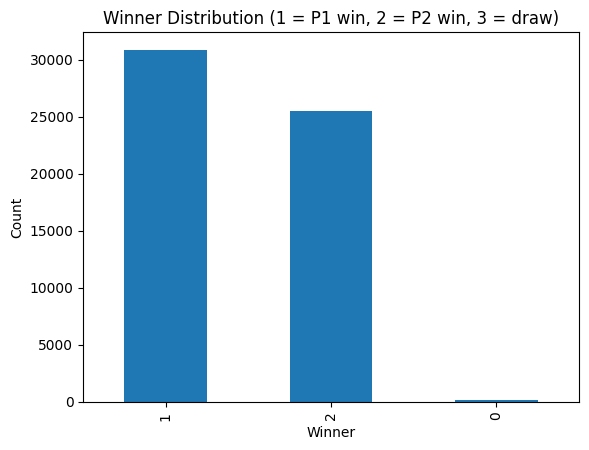

,proportion
winner,
1,0.545418
2,0.451136
0,0.003446


In [ ]:
import matplotlib.pyplot as plt

battles_df["winner"].value_counts().plot(kind="bar")
plt.title("Winner Distribution (1 = P1 win, 2 = P2 win, 3 = draw)")
plt.xlabel("Winner")
plt.ylabel("Count")
plt.show()

battles_df["winner"].value_counts(normalize=True)

Ensure every deck contains exactly 8 cards

In [ ]:
battles_df["p1_len"] = battles_df["player1_deck"].apply(lambda x: len(eval(x)))
battles_df["p2_len"] = battles_df["player2_deck"].apply(lambda x: len(eval(x)))

print(battles_df["p1_len"].value_counts())
print(battles_df["p2_len"].value_counts())

p1_len
8    56586
Name: count, dtype: int64
p2_len
8    56586
Name: count, dtype: int64


Explore card frequency across all decks

In [ ]:
from collections import Counter

card_counter = Counter()

for deck in battles_df["player1_deck"]:
    card_counter.update(eval(deck))

for deck in battles_df["player2_deck"]:
    card_counter.update(eval(deck))

card_freq_df = pd.DataFrame(card_counter.items(), columns=["card_id", "frequency"])
card_freq_df = card_freq_df.merge(cards_df, on="card_id")
card_freq_df.sort_values("frequency", ascending=False).head(20)

,card_id,frequency,name,elixir_cost,rarity,archetype
12,28000015,47971,Barbarian Barrel,2.0,epic,Spell
11,26000010,34893,Skeletons,1.0,common,Troop
9,26000050,34483,Royal Ghost,3.0,legendary,Troop
4,28000000,33112,Fireball,4.0,rare,Spell
36,26000084,21297,Electro Spirit,1.0,common,Troop
79,28000008,18819,Zap,2.0,common,Spell
33,28000011,18807,The Log,2.0,legendary,Spell
65,28000001,18416,Arrows,3.0,common,Spell
3,28000026,18256,Vines,3.0,epic,Spell
0,26000015,16940,Baby Dragon,4.0,epic,Troop


Plot top 10 most frequent cards

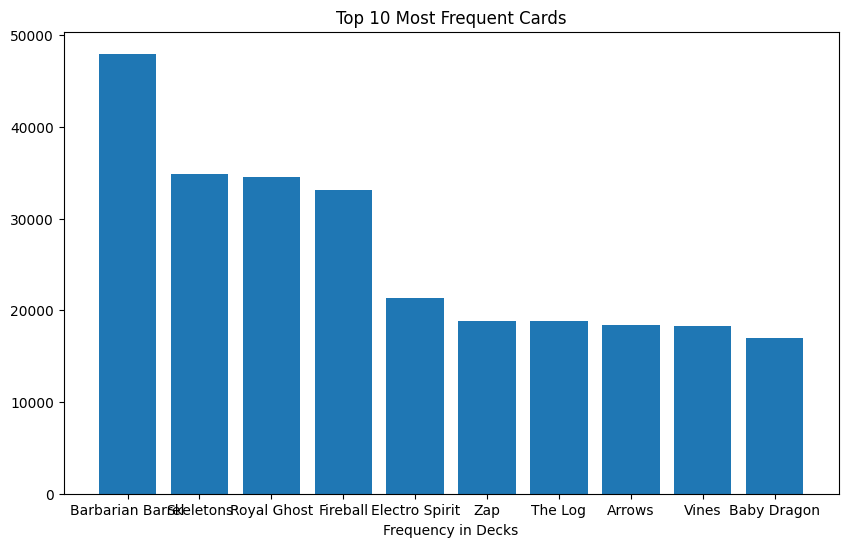

In [ ]:
top_cards = card_freq_df.sort_values("frequency", ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.bar(top_cards["name"], top_cards["frequency"])
plt.title("Top 10 Most Frequent Cards")
plt.xlabel("Frequency in Decks")
plt.show()

Analyze deck elixir averages

In [ ]:
def avg_elixir(deck):
  ids = eval(deck)
  return cards_df.set_index("card_id").loc[ids]["elixir_cost"].mean()

battles_df["p1_elixir"] = battles_df["player1_deck"].apply(avg_elixir)
battles_df["p2_elixir"] = battles_df["player2_deck"].apply(avg_elixir)

battles_df[["p1_elixir", "p2_elixir"]].describe()

,p1_elixir,p2_elixir
count,56586.00000,56586.000000
mean,3.52151,3.547760
std,0.57361,0.569051
min,1.75000,1.750000
25%,3.00000,3.000000
50%,3.62500,3.625000
75%,4.00000,4.000000
max,5.37500,6.250000


<function matplotlib.pyplot.show(close=None, block=None)>

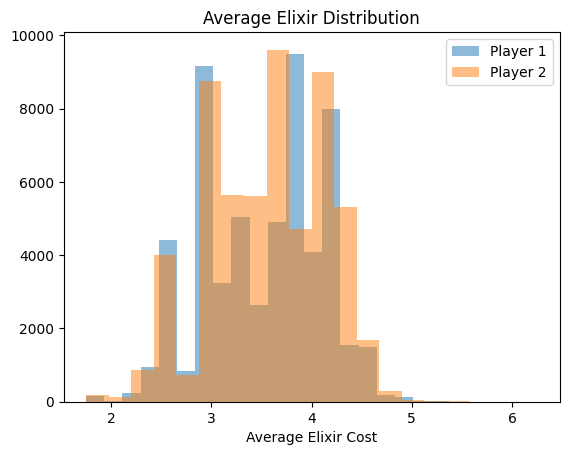

In [ ]:
plt.hist(battles_df["p1_elixir"], bins=20, alpha=0.5, label="Player 1")
plt.hist(battles_df["p2_elixir"], bins=20, alpha=0.5, label="Player 2")
plt.title("Average Elixir Distribution")
plt.xlabel("Average Elixir Cost")
plt.legend()
plt.show

See if cheaper or more expensive decks tend to win

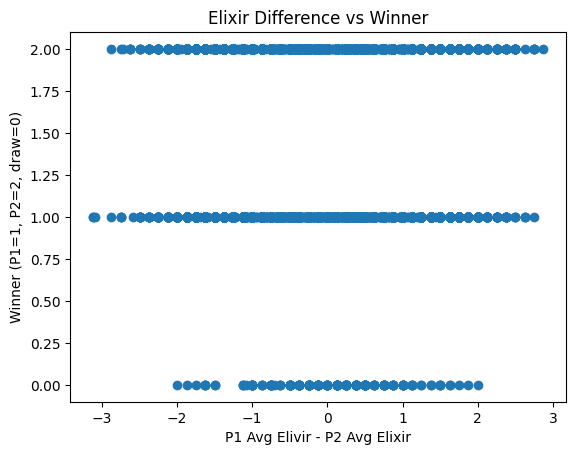

,winner
elixir_diff,
False,1.446209
True,1.449474


In [ ]:
battles_df["elixir_diff"] = battles_df["p1_elixir"] - battles_df["p2_elixir"]

plt.scatter(battles_df["elixir_diff"], battles_df["winner"])
plt.title("Elixir Difference vs Winner")
plt.xlabel("P1 Avg Elivir - P2 Avg Elixir")
plt.ylabel("Winner (P1=1, P2=2, draw=0)")
plt.show()

battles_df.groupby(battles_df["elixir_diff"] > 0)["winner"].mean()

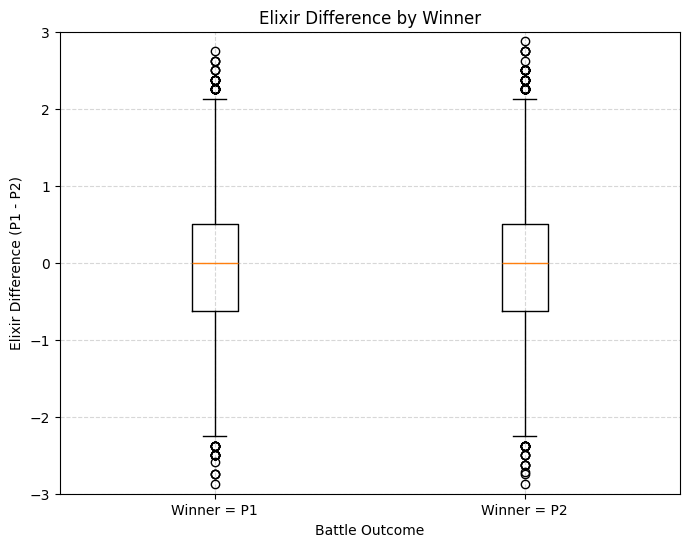

In [ ]:
battles_df["elixir_diff"] = battles_df["p1_elixir"] - battles_df["p2_elixir"]

plt.figure(figsize=(8,6))

data = [
    battles_df[battles_df["winner"]==1]["elixir_diff"],
    battles_df[battles_df["winner"]==2]["elixir_diff"]
]

plt.boxplot(data, labels=["Winner = P1", "Winner = P2"])
plt.title("Elixir Difference by Winner")
plt.xlabel("Battle Outcome")
plt.ylabel("Elixir Difference (P1 - P2)")

plt.ylim(-3, 3)
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

Exploring deck archetypes

In [ ]:
def archetype_counts(deck):
  ids = eval(deck)
  types = cards_df.set_index("card_id").loc[ids]["archetype"]
  return types.value_counts()

# example distribution
archetype_counts(battles_df["player1_deck"].iloc[0])

,count
archetype,
Troop,5
Spell,2
Building,1


In [ ]:
arch_counter = Counter()

for deck in battles_df["player1_deck"]:
  arch_counter.update(cards_df.set_index("card_id").loc[eval(deck)]["archetype"])

for deck in battles_df["player2_deck"]:
  arch_counter.update(cards_df.set_index("card_id").loc[eval(deck)]["archetype"])

arch_counter

Counter({'Troop': 593757, 'Spell': 243544, 'Building': 68075})

Time based trends of battles

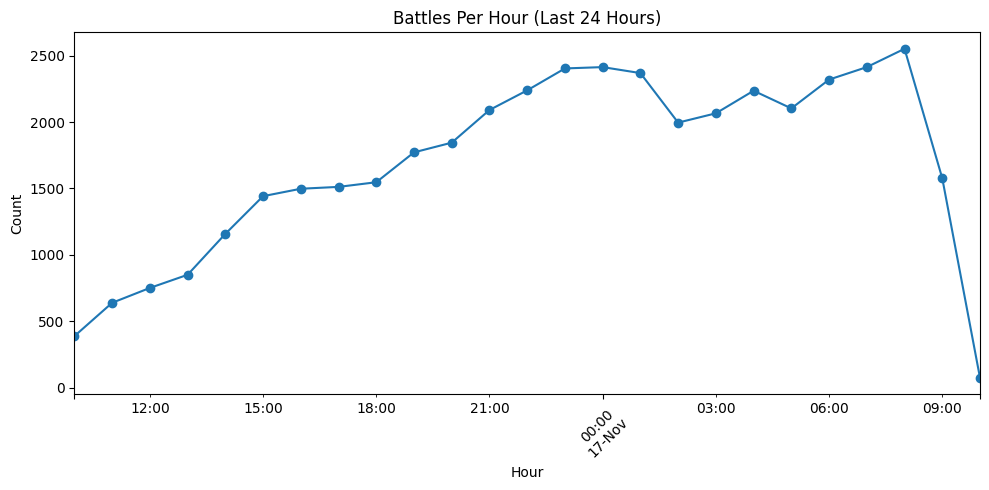

In [ ]:
#battles_df["battle_time"] = pd.to_datetime(battles_df["battle_time"], format="%Y%m%dT%H%M%S.%fZ")
#battles_df["date"] = battles_df["battle_time"].dt.date

#battles_df.groupby("date").size().plot()
#plt.title("Battles Over Time")
#plt.ylabel("Count")
#plt.show()

battles_df["battle_time"] = pd.to_datetime(
    battles_df["battle_time"],
    format="%Y%m%dT%H%M%S.%fZ",
    errors="coerce"
)

battles_df["hour"] = battles_df["battle_time"].dt.floor("H")

last_24 = battles_df[battles_df["battle_time"] >= battles_df["battle_time"].max() - pd.Timedelta(hours=24)]

last_24.groupby("hour").size().plot(kind="line", marker="o", figsize=(10,5))
plt.title("Battles Per Hour (Last 24 Hours)")
plt.xlabel("Hour")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Training the Logistic Regression Model

In [ ]:
import numpy as np
import json
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

Data preperation

In [ ]:
# Load data and remove draws
battles_df = pd.read_sql_query("SELECT * FROM battles;", conn)
cards_df = pd.read_sql_query("SELECT * FROM cards;", conn)

df = battles_df[battles_df['winner'] != 0].copy()
df['winner_binary'] = (df['winner'] == 1).astype(int)

# Parse JSON decks
df['p1_deck'] = df['player1_deck'].apply(lambda x: json.loads(x) if isinstance(x, str) else eval(x))
df['p2_deck'] = df['player2_deck'].apply(lambda x: json.loads(x) if isinstance(x, str) else eval(x))
# Evolution features
df['player1_evos_parsed'] = df['player1_evos'].apply(lambda x: json.loads(x) if isinstance(x, str) else eval(x) if pd.notna(x) and x != '[]' else [])
df['player2_evos_parsed'] = df['player2_evos'].apply(lambda x: json.loads(x) if isinstance(x, str) else eval(x) if pd.notna(x) and x != '[]' else [])

print(f"Total matches: {len(df)}")
print(f"Player 1 win rate: {df['winner_binary'].mean()*100:.2f}%")

Total matches: 56391
Player 1 win rate: 54.73%


Feature Engineering

In [ ]:
# Get card metadata
all_cards = sorted(cards_df['card_id'].unique())
card_elixir = cards_df.set_index('card_id')['elixir_cost'].to_dict()
card_rarity = cards_df.set_index('card_id')['rarity'].to_dict()
card_archetype = cards_df.set_index('card_id')['archetype'].to_dict()

# Build feature matrix
features_list = []

for _, row in df.iterrows():
    features = {}

    # One-hot encode cards
    for card_id in all_cards:
        features[f'p1_has_{card_id}'] = int(card_id in row['p1_deck'])
        features[f'p2_has_{card_id}'] = int(card_id in row['p2_deck'])

    # Elixir features
    p1_elixir = [card_elixir.get(c, 0) for c in row['p1_deck']]
    p2_elixir = [card_elixir.get(c, 0) for c in row['p2_deck']]
    features['p1_avg_elixir'] = np.mean(p1_elixir)
    features['p2_avg_elixir'] = np.mean(p2_elixir)
    features['elixir_diff'] = features['p1_avg_elixir'] - features['p2_avg_elixir']

    # Rarity features
    p1_rarities = Counter([card_rarity.get(c, 'unknown') for c in row['p1_deck']])
    p2_rarities = Counter([card_rarity.get(c, 'unknown') for c in row['p2_deck']])

    for rarity in ['common', 'rare', 'epic', 'legendary']:
        features[f'p1_{rarity}'] = p1_rarities.get(rarity, 0)
        features[f'p2_{rarity}'] = p2_rarities.get(rarity, 0)

    # archetype features
    p1_archetypes = Counter([card_archetype.get(c, 'unknown') for c in row['p1_deck']])
    p2_archetypes = Counter([card_archetype.get(c, 'unknown') for c in row['p2_deck']])

    features['p1_spell_count'] = p1_archetypes.get('Spell', 0)
    features['p2_spell_count'] = p2_archetypes.get('Spell', 0)
    features['p1_building_count'] = p1_archetypes.get('Building', 0)
    features['p2_building_count'] = p2_archetypes.get('Building', 0)
    features['spell_advantage'] = features['p1_spell_count'] - features['p2_spell_count']

    # Card overlap
    features['card_overlap'] = len(set(row['p1_deck']).intersection(set(row['p2_deck'])))

    # Evo features
    features['p1_evo_count'] = len(row['player1_evos_parsed'])
    features['p2_evo_count'] = len(row['player2_evos_parsed'])
    features['evo_advantage'] = features['p1_evo_count'] - features['p2_evo_count']

    features_list.append(features)

X = pd.DataFrame(features_list)
y = df['winner_binary'].values

print(f"Feature matrix shape: {X.shape}")

Feature matrix shape: (56391, 270)


Train model

In [ ]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fill any NaN values with 0
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

# Scale numerical features
numerical_cols = ['p1_avg_elixir', 'p2_avg_elixir', 'elixir_diff',
                  'p1_common', 'p2_common', 'p1_rare', 'p2_rare',
                  'p1_epic', 'p2_epic', 'p1_legendary', 'p2_legendary', 'card_overlap']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test[numerical_cols])

#Train logistic regression
model = LogisticRegression(max_iter=1000, random_state=42, C=0.1, penalty='l2')
model.fit(X_train_scaled, y_train)

LogisticRegression(C=0.1, max_iter=1000, random_state=42)

Evaluation

In [ ]:
# Make predictions
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

# Calculate metrics
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

print("MODEL PERFORMANCE")
print(f"Training Accuracy: {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Test Accuracy:     {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Test F1 Score:     {test_f1:.4f}")
print(f"Overfitting Gap:   {abs(train_acc - test_acc):.4f}")

print("\n" + classification_report(y_test, y_test_pred,
                                    target_names=['Player 2 Wins', 'Player 1 Wins']))

MODEL PERFORMANCE
Training Accuracy: 0.5533 (55.33%)
Test Accuracy:     0.5412 (54.12%)
Test F1 Score:     0.6787
Overfitting Gap:   0.0122

               precision    recall  f1-score   support

Player 2 Wins       0.47      0.13      0.20      5106
Player 1 Wins       0.55      0.89      0.68      6173

     accuracy                           0.54     11279
    macro avg       0.51      0.51      0.44     11279
 weighted avg       0.52      0.54      0.46     11279



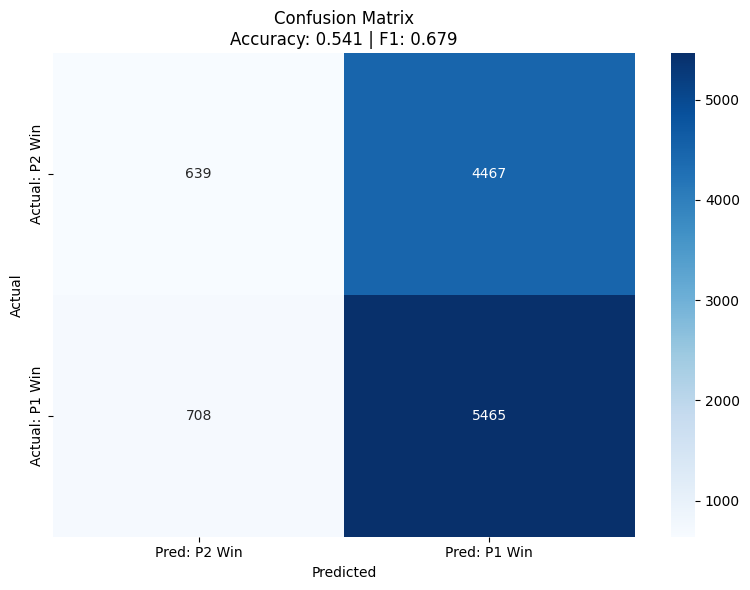

True Negatives:  639
False Positives: 4,467
False Negatives: 708
True Positives:  5,465


In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred: P2 Win', 'Pred: P1 Win'],
            yticklabels=['Actual: P2 Win', 'Actual: P1 Win'])
plt.title(f'Confusion Matrix\nAccuracy: {test_acc:.3f} | F1: {test_f1:.3f}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

print(f"True Negatives:  {cm[0,0]:,}")
print(f"False Positives: {cm[0,1]:,}")
print(f"False Negatives: {cm[1,0]:,}")
print(f"True Positives:  {cm[1,1]:,}")

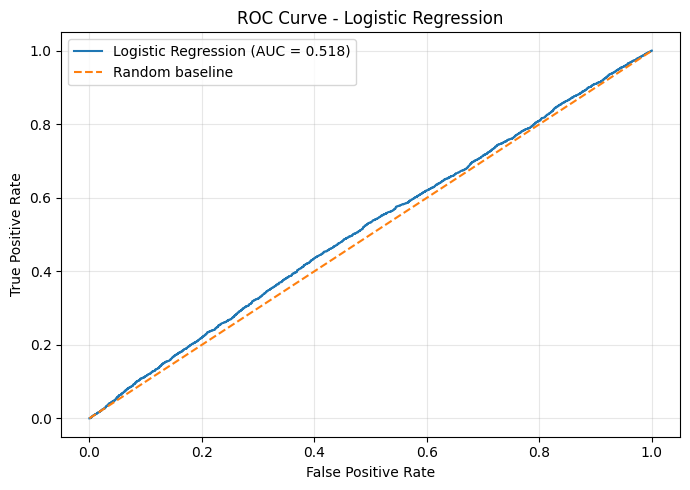

In [ ]:
# ROC curve and AUC for Logistic Regression
from sklearn.metrics import roc_curve, auc

# Predicted probabilities for the positive class (Player 1 wins)
y_test_proba_lr = model.predict_proba(X_test_scaled)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_test_proba_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_lr:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Feature Importance

In [ ]:
# Get top features
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model.coef_[0],
    'abs_coef': np.abs(model.coef_[0])
}).sort_values('abs_coef', ascending=False)

# Map card IDs to names
card_names = cards_df.set_index('card_id')['name'].to_dict()

def format_feature(feat):
    if 'has_' in feat:
        player, card_id = feat.split('_has_')
        card_name = card_names.get(int(card_id), f"Card{card_id}")
        return f"{player.upper()}: {card_name}"
    return feat

feature_importance['readable'] = feature_importance['feature'].apply(format_feature)

print("\nTop 20 Most Influential Features:")
print("(Positive = favors P1, Negative = favors P2)\n")
print(feature_importance[['readable', 'coefficient']].head(20).to_string(index=False))


Top 20 Most Influential Features:
(Positive = favors P1, Negative = favors P2)

             readable  coefficient
   P2: Spirit Empress     0.269613
     P2: Goblin Giant     0.249688
      P1: Dark Prince     0.242916
     P1: Elixir Golem     0.228571
 P1: Three Musketeers    -0.223376
        P1: Ram Rider     0.208648
   P1: Royal Delivery    -0.206900
      P1: Mega Minion    -0.193108
   P2: Electro Dragon     0.192272
P2: Goblin Demolisher     0.189957
  P1: Suspicious Bush     0.178316
      P2: Firecracker     0.178252
   P1: Goblin Machine     0.173122
     P2: Goblin Drill     0.167741
   P2: Goblin Machine     0.163197
     P1: Magic Archer    -0.163138
 P2: Three Musketeers     0.161322
        P1: Berserker     0.160889
   P1: Spirit Empress    -0.160194
     P1: Goblin Giant    -0.159942


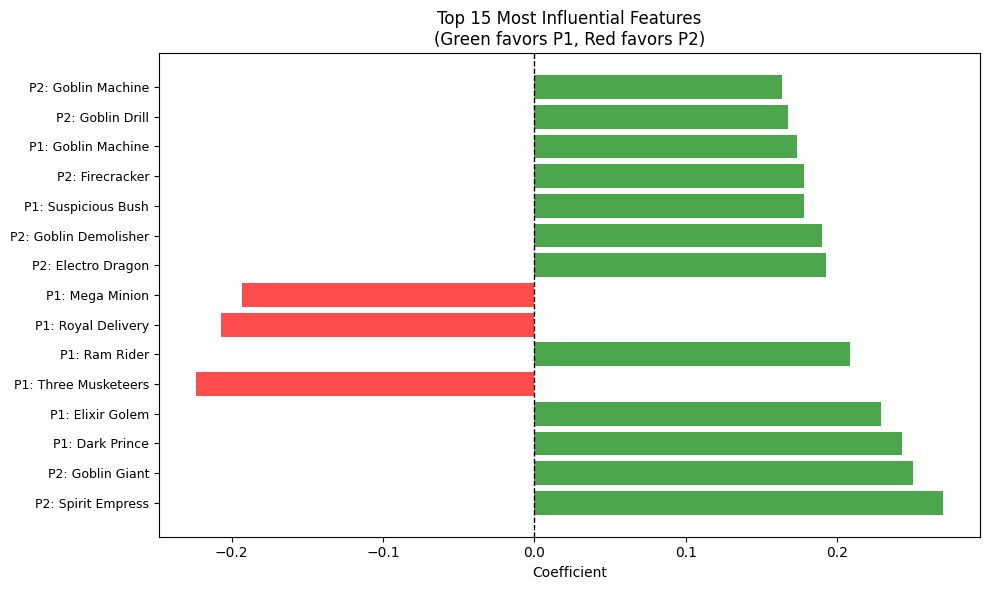

In [ ]:
# Visualize top features
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))
colors = ['green' if c > 0 else 'red' for c in top_features['coefficient']]
plt.barh(range(len(top_features)), top_features['coefficient'], color=colors, alpha=0.7)
plt.yticks(range(len(top_features)), top_features['readable'], fontsize=9)
plt.xlabel('Coefficient')
plt.title('Top 15 Most Influential Features\n(Green favors P1, Red favors P2)')
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

# Logistic Regression with Polynomials

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Create polynomial features (degree=2 for interactions)
poly = PolynomialFeatures(degree=3, include_bias=False, interaction_only=False)

print("Creating polynomial features...")
X_train_numerical = X_train[numerical_cols]
X_test_numerical = X_test[numerical_cols]

X_train_poly = poly.fit_transform(X_train_numerical)
X_test_poly = poly.transform(X_test_numerical)

print(f"Original numerical features: {len(numerical_cols)}")
print(f"Polynomial features: {X_train_poly.shape[1]}")

# Combine polynomial features with original one-hot encoded cards
one_hot_cols = [col for col in X.columns if col not in numerical_cols]
X_train_combined = np.hstack([X_train[one_hot_cols].values, X_train_poly])
X_test_combined = np.hstack([X_test[one_hot_cols].values, X_test_poly])

print(f"Total features (cards + polynomials): {X_train_combined.shape[1]}")

# Scale the combined features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_combined)
X_test_scaled = scaler.transform(X_test_combined)

# Train logistic regression
model = LogisticRegression(max_iter=2000, random_state=42, C=0.1)
print("\nTraining Logistic Regression with Polynomial Features...")
model.fit(X_train_scaled, y_train)
print("Model trained!")

Creating polynomial features...
Original numerical features: 12
Polynomial features: 454
Total features (cards + polynomials): 712

Training Logistic Regression with Polynomial Features...
Model trained!


In [ ]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
# Make predictions
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)
y_test_proba = model.predict_proba(X_test_scaled)[:, 1]  # Probability of P1 winning

# Calculate metrics
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_proba)

print("POLYNOMIAL LOGISTIC REGRESSION PERFORMANCE")
print(f"Training Accuracy: {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Test Accuracy:     {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Test F1 Score:     {test_f1:.4f}")
print(f"Test AUC Score:    {test_auc:.4f}")
print(f"Overfitting Gap:   {abs(train_acc - test_acc):.4f}")

print("\n" + classification_report(y_test, y_test_pred,
                                    target_names=['Player 2 Wins', 'Player 1 Wins']))

POLYNOMIAL LOGISTIC REGRESSION PERFORMANCE
Training Accuracy: 0.5694 (56.94%)
Test Accuracy:     0.5465 (54.65%)
Test F1 Score:     0.6599
Test AUC Score:    0.5381
Overfitting Gap:   0.0229

               precision    recall  f1-score   support

Player 2 Wins       0.50      0.24      0.32      5106
Player 1 Wins       0.56      0.80      0.66      6173

     accuracy                           0.55     11279
    macro avg       0.53      0.52      0.49     11279
 weighted avg       0.53      0.55      0.51     11279



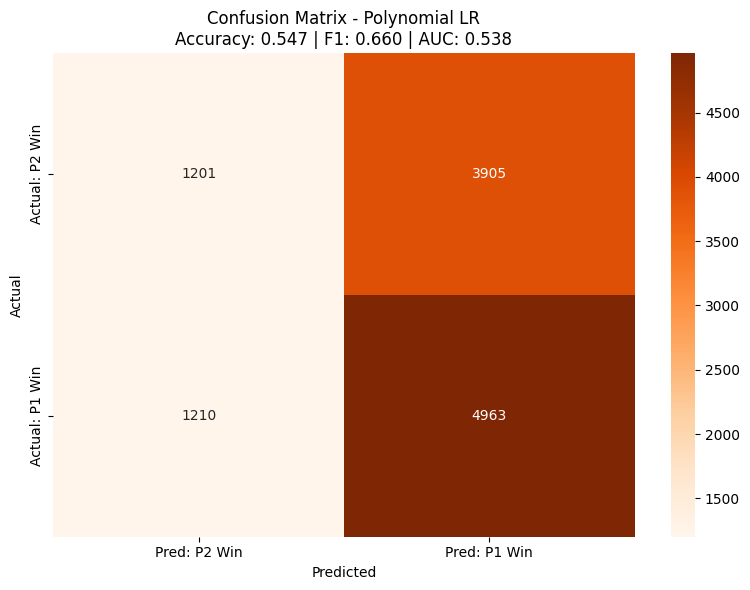


True Negatives:  1,201
False Positives: 3,905
False Negatives: 1,210
True Positives:  4,963


In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Pred: P2 Win', 'Pred: P1 Win'],
            yticklabels=['Actual: P2 Win', 'Actual: P1 Win'])
plt.title(f'Confusion Matrix - Polynomial LR\nAccuracy: {test_acc:.3f} | F1: {test_f1:.3f} | AUC: {test_auc:.3f}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

print(f"\nTrue Negatives:  {cm[0,0]:,}")
print(f"False Positives: {cm[0,1]:,}")
print(f"False Negatives: {cm[1,0]:,}")
print(f"True Positives:  {cm[1,1]:,}")

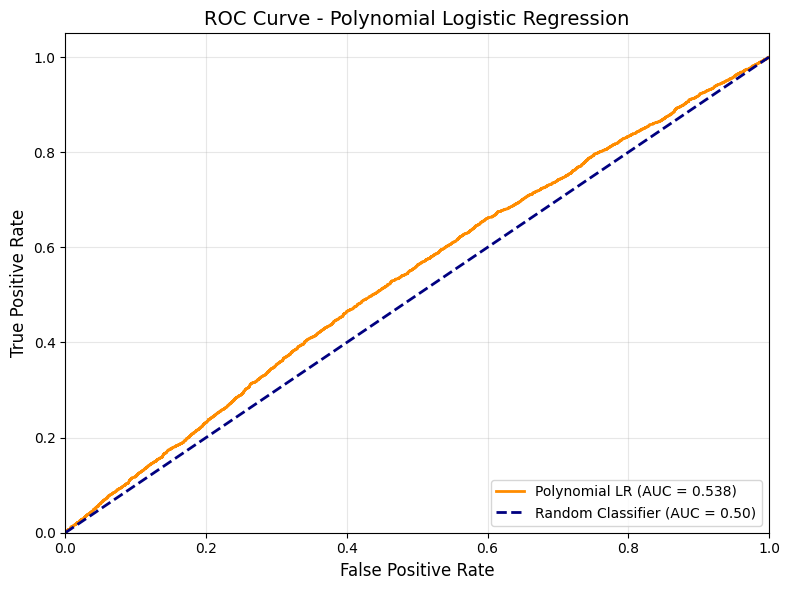

In [ ]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Polynomial LR (AUC = {test_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve - Polynomial Logistic Regression', fontsize=14)
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Training the SVM Models


In [ ]:
# -------------------------------------------------
# SUPPORT VECTOR MACHINES (Linear & RBF Kernel)
# -------------------------------------------------
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, auc
)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("SVM models using the same scaled data as Logistic Regression:")
print("Train:", X_train_scaled.shape, "Test:", X_test_scaled.shape)

SVM models using the same scaled data as Logistic Regression:
Train: (45112, 712) Test: (11279, 712)



Training Linear SVM...
Done!

=== Linear SVM Performance ===
Accuracy:  0.5234
Precision: 0.5673
Recall:    0.5440
F1 Score:  0.5554

              precision    recall  f1-score   support

     P2 Wins       0.47      0.50      0.49      5106
     P1 Wins       0.57      0.54      0.56      6173

    accuracy                           0.52     11279
   macro avg       0.52      0.52      0.52     11279
weighted avg       0.53      0.52      0.52     11279



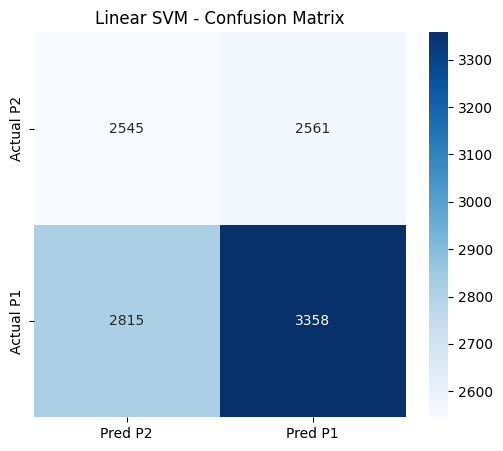

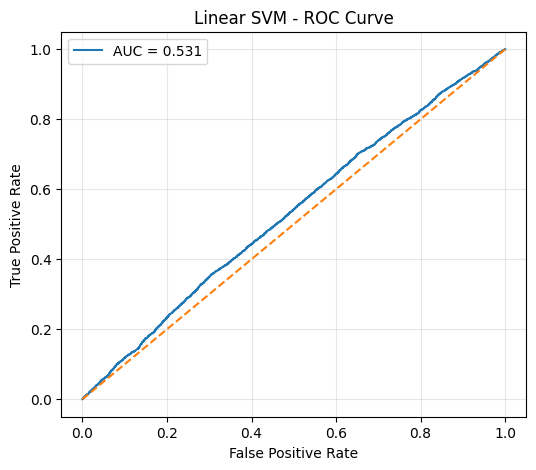

In [ ]:
# ------ LINEAR SVM ------
svm_linear = LinearSVC(
    C=1.0,
    class_weight="balanced",
    loss="hinge",
    random_state=42
)

print("\nTraining Linear SVM...")
svm_linear.fit(X_train_scaled, y_train)
print("Done!")

# Predictions + decision scores
y_test_pred_lin = svm_linear.predict(X_test_scaled)
y_test_score_lin = svm_linear.decision_function(X_test_scaled)

# Metrics
lin_acc = accuracy_score(y_test, y_test_pred_lin)
lin_prec = precision_score(y_test, y_test_pred_lin)
lin_rec = recall_score(y_test, y_test_pred_lin)
lin_f1 = f1_score(y_test, y_test_pred_lin)

print("\n=== Linear SVM Performance ===")
print(f"Accuracy:  {lin_acc:.4f}")
print(f"Precision: {lin_prec:.4f}")
print(f"Recall:    {lin_rec:.4f}")
print(f"F1 Score:  {lin_f1:.4f}")
print("\n" + classification_report(y_test, y_test_pred_lin,
                                  target_names=['P2 Wins', 'P1 Wins']))

# Confusion Matrix
cm_lin = confusion_matrix(y_test, y_test_pred_lin)
plt.figure(figsize=(6,5))
sns.heatmap(cm_lin, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Pred P2', 'Pred P1'],
            yticklabels=['Actual P2', 'Actual P1'])
plt.title("Linear SVM - Confusion Matrix")
plt.show()

# ROC Curve
fpr_lin, tpr_lin, _ = roc_curve(y_test, y_test_score_lin)
roc_auc_lin = auc(fpr_lin, tpr_lin)

plt.figure(figsize=(6,5))
plt.plot(fpr_lin, tpr_lin, label=f"AUC = {roc_auc_lin:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.title("Linear SVM - ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=.3)
plt.show()


Training RBF SVM ...
Training complete!

=== RBF SVM (Test Set) ===
Accuracy:  0.5621
Precision: 0.6054
Recall:    0.5740
F1 Score:  0.5893

Classification report:
              precision    recall  f1-score   support

     P2 wins       0.52      0.55      0.53      5106
     P1 wins       0.61      0.57      0.59      6173

    accuracy                           0.56     11279
   macro avg       0.56      0.56      0.56     11279
weighted avg       0.56      0.56      0.56     11279



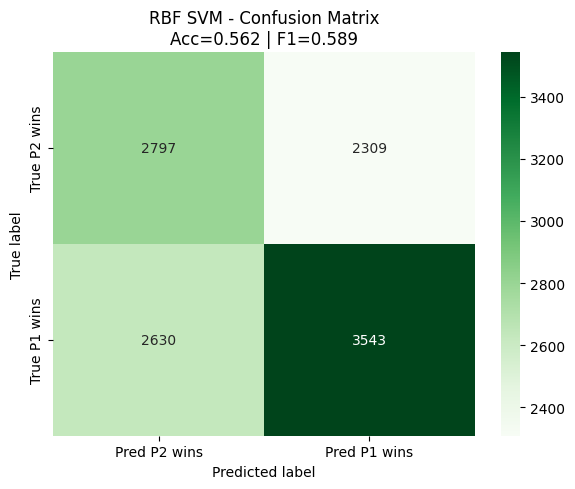

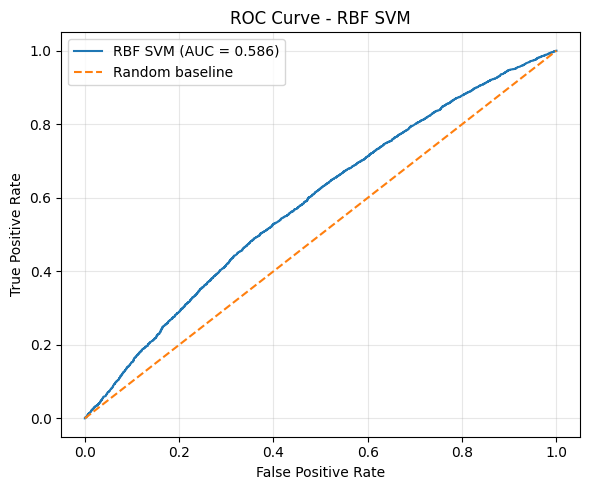

In [ ]:
# --- RBF Kernel SVM ---
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, auc
)
import matplotlib.pyplot as plt
import seaborn as sns

# RBF SVM model
svm_rbf = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    class_weight='balanced',
    probability=False,
    random_state=42
)

print("Training RBF SVM ...")
svm_rbf.fit(X_train_scaled, y_train)
print("Training complete!")

# Predictions on test data
y_test_pred_rbf = svm_rbf.predict(X_test_scaled)
# Continuous scores for ROC/AUC
y_test_score_rbf = svm_rbf.decision_function(X_test_scaled)

# Metrics
rbf_acc  = accuracy_score(y_test, y_test_pred_rbf)
rbf_prec = precision_score(y_test, y_test_pred_rbf)
rbf_rec  = recall_score(y_test, y_test_pred_rbf)
rbf_f1   = f1_score(y_test, y_test_pred_rbf)

print("\n=== RBF SVM (Test Set) ===")
print(f"Accuracy:  {rbf_acc:.4f}")
print(f"Precision: {rbf_prec:.4f}")
print(f"Recall:    {rbf_rec:.4f}")
print(f"F1 Score:  {rbf_f1:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_test_pred_rbf,
                            target_names=["P2 wins", "P1 wins"]))

# Confusion Matrix
cm_rbf = confusion_matrix(y_test, y_test_pred_rbf)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rbf, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Pred P2 wins", "Pred P1 wins"],
            yticklabels=["True P2 wins", "True P1 wins"])
plt.title(f"RBF SVM - Confusion Matrix\nAcc={rbf_acc:.3f} | F1={rbf_f1:.3f}")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

# ROC Curve + AUC
fpr_rbf, tpr_rbf, _ = roc_curve(y_test, y_test_score_rbf)
roc_auc_rbf = auc(fpr_rbf, tpr_rbf)

plt.figure(figsize=(6, 5))
plt.plot(fpr_rbf, tpr_rbf, label=f"RBF SVM (AUC = {roc_auc_rbf:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - RBF SVM")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Training Random Forest Model (Bagging)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Split data (same as before)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fill NaN values
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

# 300 trees, unlimited depth (max_depth=None), min_samples_split = 2, min_samples_leaf = 1
# Train Random Forest (no scaling needed!)
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

print("Training Random Forest...")
rf_model.fit(X_train, y_train)
print("Model trained!")

Training Random Forest...
Model trained!


Evaluate random forest model

RANDOM FOREST PERFORMANCE
Training Accuracy: 0.9071 (90.71%)
Test Accuracy:     0.5617 (56.17%)
Test F1 Score:     0.6233
Overfitting Gap:   0.3454

               precision    recall  f1-score   support

Player 2 Wins       0.52      0.44      0.48      5106
Player 1 Wins       0.59      0.66      0.62      6173

     accuracy                           0.56     11279
    macro avg       0.55      0.55      0.55     11279
 weighted avg       0.56      0.56      0.56     11279



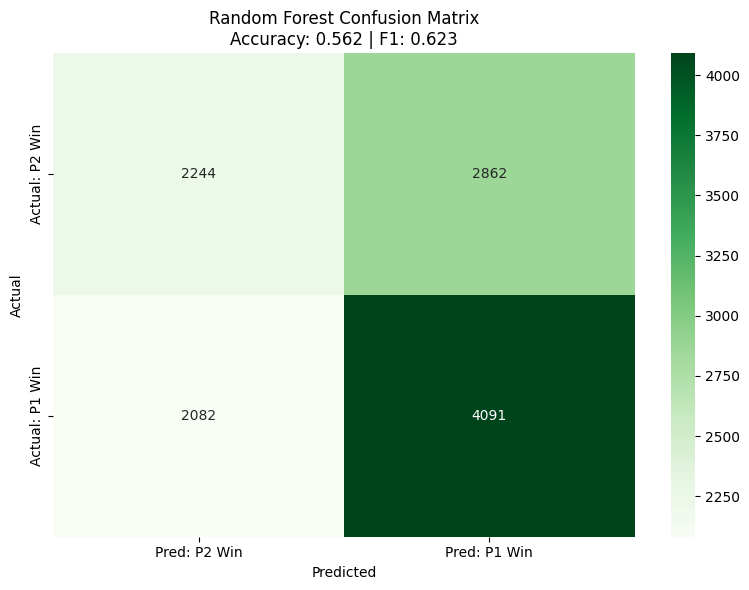

In [ ]:
# Make predictions
y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)

# Calculate metrics
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

print("RANDOM FOREST PERFORMANCE")
print(f"Training Accuracy: {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Test Accuracy:     {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Test F1 Score:     {test_f1:.4f}")
print(f"Overfitting Gap:   {abs(train_acc - test_acc):.4f}")

print("\n" + classification_report(y_test, y_test_pred,
                                    target_names=['Player 2 Wins', 'Player 1 Wins']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Pred: P2 Win', 'Pred: P1 Win'],
            yticklabels=['Actual: P2 Win', 'Actual: P1 Win'])
plt.title(f'Random Forest Confusion Matrix\nAccuracy: {test_acc:.3f} | F1: {test_f1:.3f}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

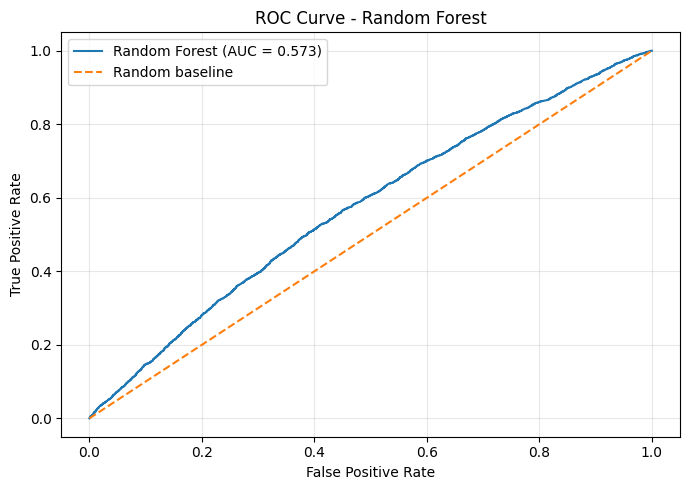

In [ ]:
# ROC curve and AUC for Random Forest
y_test_proba_rf = rf_model.predict_proba(X_test)[:, 1]

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_test_proba_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

plt.figure(figsize=(7, 5))
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_rf:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Training Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fill NaN values
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

# Train Decision Tree with better parameters
dt_model = DecisionTreeClassifier(
    max_depth=20,  # Increased from 10
    min_samples_split=50,  # Reduced from 100
    min_samples_leaf=20,  # Reduced from 50
    random_state=42,
    class_weight='balanced'
)

print("Training Decision Tree...")
dt_model.fit(X_train, y_train)
print(f"Tree depth: {dt_model.get_depth()}")
print(f"Number of leaves: {dt_model.get_n_leaves()}")
print("Model trained!")

Training Decision Tree...
Tree depth: 20
Number of leaves: 767
Model trained!


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report, confusion_matrix
)

# Make predictions
y_train_pred = dt_model.predict(X_train)
y_test_pred = dt_model.predict(X_test)
y_test_proba = dt_model.predict_proba(X_test)[:, 1]

# Calculate metrics
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_proba)

print("DECISION TREE PERFORMANCE")
print(f"Training Accuracy: {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Test Accuracy:     {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Test F1 Score:     {test_f1:.4f}")
print(f"Test AUC Score:    {test_auc:.4f}")
print(f"Overfitting Gap:   {abs(train_acc - test_acc):.4f}")

print("\n" + classification_report(y_test, y_test_pred,
                                    target_names=['Player 2 Wins', 'Player 1 Wins']))

DECISION TREE PERFORMANCE
Training Accuracy: 0.6189 (61.89%)
Test Accuracy:     0.5410 (54.10%)
Test F1 Score:     0.6108
Test AUC Score:    0.5376
Overfitting Gap:   0.0779

               precision    recall  f1-score   support

Player 2 Wins       0.49      0.40      0.44      5106
Player 1 Wins       0.57      0.66      0.61      6173

     accuracy                           0.54     11279
    macro avg       0.53      0.53      0.53     11279
 weighted avg       0.53      0.54      0.53     11279



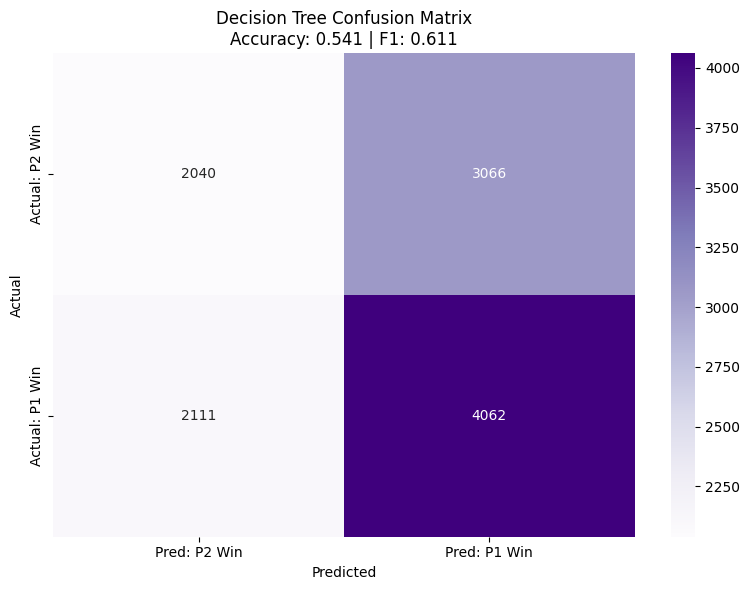

True Negatives:  2,040
False Positives: 3,066
False Negatives: 2,111
True Positives:  4,062


In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Pred: P2 Win', 'Pred: P1 Win'],
            yticklabels=['Actual: P2 Win', 'Actual: P1 Win'])
plt.title(f'Decision Tree Confusion Matrix\nAccuracy: {test_acc:.3f} | F1: {test_f1:.3f}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

print(f"True Negatives:  {cm[0,0]:,}")
print(f"False Positives: {cm[0,1]:,}")
print(f"False Negatives: {cm[1,0]:,}")
print(f"True Positives:  {cm[1,1]:,}")

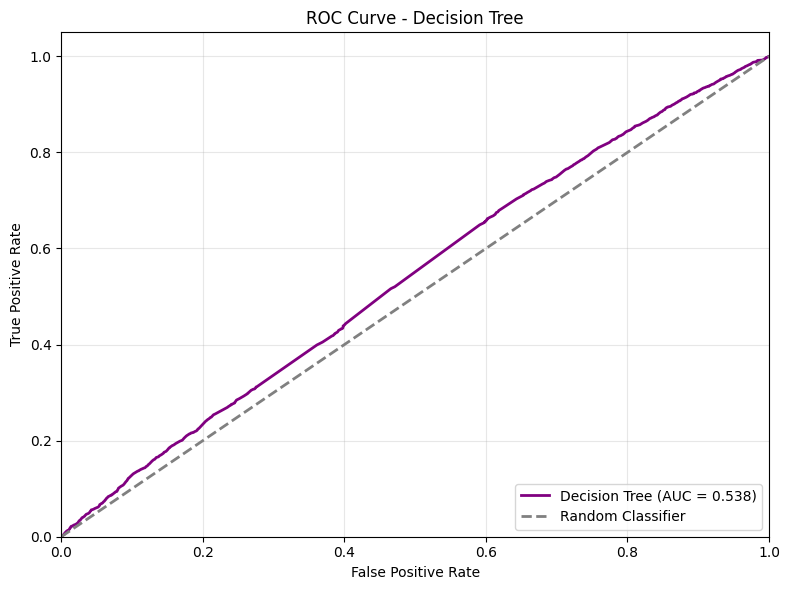

In [ ]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='purple', lw=2, label=f'Decision Tree (AUC = {test_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Grid search used to find hyperparameters on decision tree

In [ ]:
# from sklearn.model_selection import RandomizedSearchCV

# param_dist = {
#     'max_depth': range(10, 31, 1),           # 21 values
#     'min_samples_split': range(20, 201, 10), # 19 values
#     'min_samples_leaf': range(10, 51, 5),    # 9 values
#     'criterion': ['gini', 'entropy']         # 2 values
# }

# # Test only 30 random combinations instead of all
# grid_search = RandomizedSearchCV(
#     estimator=DecisionTreeClassifier(random_state=42, class_weight='balanced'),
#     param_distributions=param_dist,
#     n_iter=30,  # Try 30 random combinations
#     cv=5,
#     scoring='accuracy',
#     n_jobs=-1,
#     verbose=2,
#     random_state=42
# )

# 30 combinations × 5 folds = 150 fits
# Time: ~15-20 minutes
# print("Starting Grid Search with 5-fold Cross-Validation...")
# print(f"Testing {len(param_grid['max_depth']) * len(param_grid['min_samples_split']) * len(param_grid['min_samples_leaf']) * len(param_grid['criterion'])} combinations")

# grid_search.fit(X_train, y_train)

# print("GRID SEARCH RESULTS")
# print(f"\nBest Parameters Found:")
# for param, value in grid_search.best_params_.items():
#     print(f"  {param}: {value}")

# print(f"\nBest Cross-Validation Score: {grid_search.best_score_:.4f}")
# print(f"Best Model Test Accuracy: {grid_search.score(X_test, y_test):.4f}")

In [ ]:
# # Use the best model from grid search
# best_model = grid_search.best_estimator_

# # Predictions
# y_train_pred = best_model.predict(X_train)
# y_test_pred = best_model.predict(X_test)
# y_test_proba = best_model.predict_proba(X_test)[:, 1]

# # Metrics
# train_acc = accuracy_score(y_train, y_train_pred)
# test_acc = accuracy_score(y_test, y_test_pred)
# test_f1 = f1_score(y_test, y_test_pred)
# test_auc = roc_auc_score(y_test, y_test_proba)

# print("OPTIMIZED DECISION TREE PERFORMANCE")
# print(f"Training Accuracy: {train_acc:.4f}")
# print(f"Test Accuracy:     {test_acc:.4f}")
# print(f"Test F1 Score:     {test_f1:.4f}")
# print(f"Test AUC:          {test_auc:.4f}")
# print(f"Tree Depth:        {best_model.get_depth()}")
# print(f"Number of Leaves:  {best_model.get_n_leaves()}")

# print("\n" + classification_report(y_test, y_test_pred,
#                                     target_names=['Player 2 Wins', 'Player 1 Wins']))

# Training KNN

Create a small tuning subset for KNN

In [ ]:
from sklearn.model_selection import train_test_split

# Assuming X and y are already created from your feature engineering section
# (X = full feature matrix, y = P1_win labels)

X_lr = X.copy()
y_lr = y.copy()

X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_lr,
    y_lr,
    test_size=0.2,
    random_state=42,
    stratify=y_lr
)

# Just to sanity-check shapes:
print("X_train_lr:", X_train_lr.shape)
print("X_test_lr: ", X_test_lr.shape)
print("y_train_lr:", y_train_lr.shape)
print("y_test_lr: ", y_test_lr.shape)

X_train_lr: (45112, 270)
X_test_lr:  (11279, 270)
y_train_lr: (45112,)
y_test_lr:  (11279,)


In [ ]:
X_train_lr = X_train_lr.fillna(0)
X_test_lr  = X_test_lr.fillna(0)

In [ ]:
numeric_cols = [
    'p1_avg_elixir', 'p2_avg_elixir', 'elixir_diff',
    'p1_common', 'p2_common', 'p1_rare', 'p2_rare',
    'p1_epic', 'p2_epic', 'p1_legendary', 'p2_legendary',
    'card_overlap'
]

scaler_lr = StandardScaler()
X_train_lr_scaled = X_train_lr.copy()
X_test_lr_scaled = X_test_lr.copy()

X_train_lr_scaled[numeric_cols] = scaler_lr.fit_transform(X_train_lr[numeric_cols])
X_test_lr_scaled[numeric_cols] = scaler_lr.transform(X_test_lr[numeric_cols])


In [ ]:
from sklearn.model_selection import train_test_split

# Smaller subset just for KNN hyperparameter tuning
X_tune_knn, _, y_tune_knn, _ = train_test_split(
    X_train_lr_scaled,
    y_train_lr,
    test_size=0.8, # keep 20% of training data for tuning
    stratify=y_train_lr,
    random_state=42
)

print("KNN tuning subset shape:", X_tune_knn.shape, "Labels:", y_tune_knn.shape)

KNN tuning subset shape: (9022, 270) Labels: (9022,)


Hyperparameter tuning for KNN (GridSearchCV)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

knn_base = KNeighborsClassifier()

knn_param_grid = {
    "n_neighbors": [3, 5, 7, 11, 15],
    "weights": ["uniform", "distance"],
    "p": [1, 2]   # 1 = Manhattan, 2 = Euclidean
}

knn_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

knn_grid = GridSearchCV(
    estimator=knn_base,
    param_grid=knn_param_grid,
    scoring="f1",
    cv=knn_cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("Running KNN Grid Search...")
knn_grid.fit(X_tune_knn, y_tune_knn)

print("\nBest KNN params:", knn_grid.best_params_)
print("Best CV F1:", knn_grid.best_score_)

best_knn = knn_grid.best_estimator_

Running KNN Grid Search...
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best KNN params: {'n_neighbors': 15, 'p': 1, 'weights': 'uniform'}
Best CV F1: 0.6122011094304695


Inspect KNN tuning results

In [ ]:
knn_results = pd.DataFrame(knn_grid.cv_results_)

knn_results[[
    "param_n_neighbors",
    "param_weights",
    "param_p",
    "mean_train_score",
    "mean_test_score",
    "std_test_score"
]].sort_values("mean_test_score", ascending=False).head(10)

,param_n_neighbors,param_weights,param_p,mean_train_score,mean_test_score,std_test_score
16,15,uniform,1,0.688234,0.612201,0.004112
18,15,uniform,2,0.687480,0.609879,0.005700
14,11,uniform,2,0.698019,0.603442,0.010319
12,11,uniform,1,0.700267,0.602957,0.008926
19,15,distance,2,0.967640,0.600365,0.008260
17,15,distance,1,0.967476,0.599204,0.006285
15,11,distance,2,0.967656,0.597033,0.012194
8,7,uniform,1,0.718244,0.597021,0.002779
10,7,uniform,2,0.719498,0.594270,0.005742
13,11,distance,1,0.967476,0.593774,0.006920


Train final KNN on full training set and evaluate

Training final KNN model on full training data with best hyperparameters...

KNN (TUNED) PERFORMANCE
Training Accuracy: 0.6389
Test Accuracy:  0.5594
Precision: 0.5849
Recall:    0.6713
F1 Score:  0.6251
ROC-AUC:   0.5722
Overfitting Gap: 0.0796

Classification report:
              precision    recall  f1-score   support

     P2 wins       0.52      0.42      0.47      5106
     P1 wins       0.58      0.67      0.63      6173

    accuracy                           0.56     11279
   macro avg       0.55      0.55      0.55     11279
weighted avg       0.55      0.56      0.55     11279



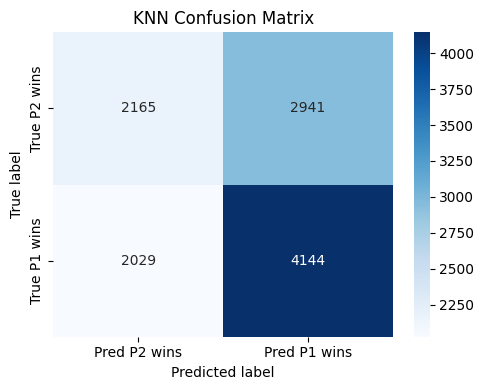

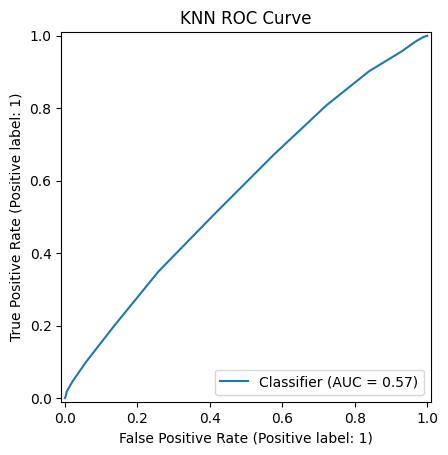

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import seaborn as sns
from sklearn.metrics import RocCurveDisplay

# Fit best KNN on full training data
print("Training final KNN model on full training data with best hyperparameters...")
best_knn.fit(X_train_lr_scaled, y_train_lr)

# Predictions on test set
y_test_pred_knn = best_knn.predict(X_test_lr_scaled)
y_test_prob_knn = best_knn.predict_proba(X_test_lr_scaled)[:, 1]

# Predictions on training set for overfitting gap
y_train_pred_knn = best_knn.predict(X_train_lr_scaled)

# Basic metrics
knn_acc  = accuracy_score(y_test_lr, y_test_pred_knn)
knn_prec = precision_score(y_test_lr, y_test_pred_knn)
knn_rec  = recall_score(y_test_lr, y_test_pred_knn)
knn_f1   = f1_score(y_test_lr, y_test_pred_knn)
knn_auc  = roc_auc_score(y_test_lr, y_test_prob_knn)
knn_train_acc = accuracy_score(y_train_lr, y_train_pred_knn)
knn_overfitting_gap = abs(knn_train_acc - knn_acc)

print("\nKNN (TUNED) PERFORMANCE")
print(f"Training Accuracy: {knn_train_acc:.4f}")
print(f"Test Accuracy:  {knn_acc:.4f}")
print(f"Precision: {knn_prec:.4f}")
print(f"Recall:    {knn_rec:.4f}")
print(f"F1 Score:  {knn_f1:.4f}")
print(f"ROC-AUC:   {knn_auc:.4f}")
print(f"Overfitting Gap: {knn_overfitting_gap:.4f}")

# Classification report
print("\nClassification report:")
print(classification_report(y_test_lr, y_test_pred_knn, target_names=["P2 wins", "P1 wins"]))

# Confusion matrix
cm_knn = confusion_matrix(y_test_lr, y_test_pred_knn)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred P2 wins", "Pred P1 wins"],
            yticklabels=["True P2 wins", "True P1 wins"])
plt.title("KNN Confusion Matrix")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

# ROC curve
RocCurveDisplay.from_predictions(y_test_lr, y_test_prob_knn)
plt.title("KNN ROC Curve")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import json
import sqlite3
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

DB_FILE = 'clash_royale.db'
TEST_SIZE = 0.2
RANDOM_STATE = 42
BATCH_SIZE = 64

def plot_training_results(history, model, X_test, y_test, model_name="Model"):
    """
    Plots accuracy/loss curves and prints classification report.
    """
    # 1. Plot Curves
    plt.figure(figsize=(12, 4))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train')
    plt.plot(history.history['val_accuracy'], label='Validation')
    plt.title(f'{model_name} Accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend()
    plt.grid(True)

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train')
    plt.plot(history.history['val_loss'], label='Validation')
    plt.title(f'{model_name} Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    # 2. Classification Report
    print(f"\n--- {model_name} Classification Report ---")
    y_pred_prob = model.predict(X_test)
    y_pred = (y_pred_prob > 0.5).astype(int)
    print(classification_report(y_test, y_pred))

    # 3. Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{model_name} Confusion Matrix')
    plt.show()

def load_data():
    conn = sqlite3.connect(DB_FILE)
    query = "SELECT * FROM battles WHERE winner != 0"
    df = pd.read_sql_query(query, conn)
    conn.close()
    return df

df_raw = load_data()
print(f"Loaded {len(df_raw)} matches.")

Loaded 56391 matches.


In [ ]:
def process_baseline_data(df):
    print("--- Processing Baseline Data ---")
    df = df.copy()
    df['label'] = df['winner'].apply(lambda x: 1 if x == 1 else 0)

    # Parse JSON
    for col in ['player1_deck', 'player2_deck', 'player1_evos', 'player2_evos']:
        df[col] = df[col].apply(lambda x: json.loads(x) if isinstance(x, str) else [])

    # Build Vocab
    all_cards = set()
    for deck in df['player1_deck']: all_cards.update(deck)
    for deck in df['player2_deck']: all_cards.update(deck)

    card_to_idx = {cid: i for i, cid in enumerate(sorted(all_cards))}
    num_cards = len(card_to_idx)

    # Vectorize
    def get_vector(row, prefix):
        vec = np.zeros(num_cards, dtype='int8')
        for cid in row[f'{prefix}_deck']:
            if cid in card_to_idx: vec[card_to_idx[cid]] = 1
        return vec

    p1_vecs = np.stack(df.apply(lambda r: get_vector(r, 'player1'), axis=1).values)
    p2_vecs = np.stack(df.apply(lambda r: get_vector(r, 'player2'), axis=1).values)
    labels = df['label'].values

    # Augment (Symmetry)
    X = np.concatenate([np.concatenate([p1_vecs, p2_vecs], axis=1),
                        np.concatenate([p2_vecs, p1_vecs], axis=1)], axis=0)
    y = np.concatenate([labels, 1-labels], axis=0)

    return X, y, X.shape[1]

X_base, y_base, input_dim = process_baseline_data(df_raw)
X_train, X_test, y_train, y_test = train_test_split(X_base, y_base, test_size=TEST_SIZE, random_state=RANDOM_STATE)

--- Processing Baseline Data ---


# **Hyperparameter Tuning**

LR/RF Dataset

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Keep a separate copy for classical models
X_lr = X.copy()
y_lr = y.copy()

X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_lr,
    y_lr,
    test_size=0.2,
    random_state=42,
    stratify=y_lr
)

# Fill NaNs
X_train_lr = X_train_lr.fillna(0)
X_test_lr = X_test_lr.fillna(0)

# Same numeric columns list you used before
numeric_cols = [
    'p1_avg_elixir', 'p2_avg_elixir', 'elixir_diff',
    'p1_common', 'p2_common', 'p1_rare', 'p2_rare',
    'p1_epic', 'p2_epic', 'p1_legendary', 'p2_legendary',
    'card_overlap'
]

scaler_lr = StandardScaler()
X_train_lr_scaled = X_train_lr.copy()
X_test_lr_scaled = X_test_lr.copy()

X_train_lr_scaled[numeric_cols] = scaler_lr.fit_transform(X_train_lr[numeric_cols])
X_test_lr_scaled[numeric_cols] = scaler_lr.transform(X_test_lr[numeric_cols])

In [ ]:
# Use a smaller subset for hyperparameter tuning since it was taking too long to run
X_tune, _, y_tune, _ = train_test_split(
    X_train_lr,
    y_train_lr,
    test_size=0.7,
    stratify=y_train_lr,
    random_state=42
)

print("Tuning subset shape:", X_tune.shape, "Labels:", y_tune.shape)


Tuning subset shape: (13533, 270) Labels: (13533,)


**Grid Search for Logistic Regression**

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression

base_lr = LogisticRegression(
    max_iter=1000,
    solver='lbfgs',
    penalty='l2',
    random_state=42
)

lr_param_grid = {
    "C": [0.01, 0.1, 1.0, 10.0],
    "class_weight": [None, "balanced"]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_grid = GridSearchCV(
    estimator=base_lr,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("Running Logistic Regression Grid Search...")
lr_grid.fit(X_train_lr_scaled, y_train_lr)

print("\nBest LR params:", lr_grid.best_params_)
print("Best CV F1:", lr_grid.best_score_)

best_lr = lr_grid.best_estimator_

y_test_pred_lr = best_lr.predict(X_test_lr_scaled)
y_test_prob_lr = best_lr.predict_proba(X_test_lr_scaled)[:, 1]

print("\nLOGISTIC REGRESSION (GRID-SEARCHED) PERFORMANCE")
print("Test Accuracy:", accuracy_score(y_test_lr, y_test_pred_lr))
print("Test F1:      ", f1_score(y_test_lr, y_test_pred_lr))
print("Test ROC-AUC: ", roc_auc_score(y_test_lr, y_test_prob_lr))

Running Logistic Regression Grid Search...
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best LR params: {'C': 0.01, 'class_weight': None}
Best CV F1: 0.6872211687461149

LOGISTIC REGRESSION (GRID-SEARCHED) PERFORMANCE
Test Accuracy: 0.5451724443656353
Test F1:       0.6907030025322561
Test ROC-AUC:  0.5190105991439287


Inspect LR Results

In [ ]:
lr_results = pd.DataFrame(lr_grid.cv_results_)
lr_results[[
    "param_C", "param_class_weight",
    "mean_train_score", "mean_test_score", "std_test_score"
]].sort_values("mean_test_score", ascending=False).head(10)

,param_C,param_class_weight,mean_train_score,mean_test_score,std_test_score
0,0.01,None,0.694672,0.687221,0.002845
2,0.10,None,0.684066,0.672842,0.002267
4,1.00,None,0.681603,0.669762,0.002390
6,10.00,None,0.681443,0.669120,0.002419
7,10.00,balanced,0.563078,0.536719,0.007497
3,0.10,balanced,0.562885,0.536369,0.008066
5,1.00,balanced,0.563008,0.535813,0.007483
1,0.01,balanced,0.561278,0.535504,0.005285


Summary
Best Parameters:
C = 0.01, class_weight = None

Performance:
Test Accuracy: 0.545
Test F1: 0.691
ROC-AUC: 0.519

Notes:

*   F1 improves sharply due to lower decision thresholding / class balance effects
*   The low AUC means the model has poor ranking ability

*   The model is still underfitting to the data

**Grid Search for Random Forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import itertools

# Split tuning subset into train/validation
X_ttrain, X_tval, y_ttrain, y_tval = train_test_split(
    X_tune, y_tune,
    # 75% tune-train, 25% tune-val
    test_size=0.25,
    stratify=y_tune,
    random_state=42
)

param_grid = {
    "n_estimators": [150, 300],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 20],
    "min_samples_leaf": [1, 5],
    "max_features": ["sqrt"],
}

def param_dicts(grid):
    keys = list(grid.keys())
    for values in itertools.product(*[grid[k] for k in keys]):
        yield dict(zip(keys, values))

results = []

print("Running manual RF hyperparameter sweep on tuning subset...")
for params in param_dicts(param_grid):
    rf = RandomForestClassifier(
        **params,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_ttrain, y_ttrain)
    y_val_pred = rf.predict(X_tval)
    f1 = f1_score(y_tval, y_val_pred)
    results.append((params, f1))
    print(f"Params: {params} -> Val F1 = {f1:.4f}")

# Select best params
best_params, best_f1 = max(results, key=lambda x: x[1])
print("\nBest params from manual sweep:", best_params)
print("Best validation F1:", best_f1)

Running manual RF hyperparameter sweep on tuning subset...
Params: {'n_estimators': 150, 'max_depth': 10, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt'} -> Val F1 = 0.5717
Params: {'n_estimators': 150, 'max_depth': 10, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 'sqrt'} -> Val F1 = 0.5773
Params: {'n_estimators': 150, 'max_depth': 10, 'min_samples_split': 20, 'min_samples_leaf': 1, 'max_features': 'sqrt'} -> Val F1 = 0.5756
Params: {'n_estimators': 150, 'max_depth': 10, 'min_samples_split': 20, 'min_samples_leaf': 5, 'max_features': 'sqrt'} -> Val F1 = 0.5662
Params: {'n_estimators': 150, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt'} -> Val F1 = 0.5970
Params: {'n_estimators': 150, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 'sqrt'} -> Val F1 = 0.5866
Params: {'n_estimators': 150, 'max_depth': 20, 'min_samples_split': 20, 'min_samples_leaf': 1, 'max_features': 'sqrt'

In [ ]:
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix

best_rf = RandomForestClassifier(
    **best_params,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Training final RF model on full training data with best hyperparameters...")
best_rf.fit(X_train_lr, y_train_lr)

y_test_pred_rf = best_rf.predict(X_test_lr)
y_test_prob_rf = best_rf.predict_proba(X_test_lr)[:, 1]

print("\nRANDOM FOREST (TUNED) PERFORMANCE")
print("Test Accuracy:", accuracy_score(y_test_lr, y_test_pred_rf))
print("Test F1:      ", f1_score(y_test_lr, y_test_pred_rf))
print("Test ROC-AUC: ", roc_auc_score(y_test_lr, y_test_prob_rf))

print("\nClassification report:")
print(classification_report(y_test_lr, y_test_pred_rf, target_names=["P2 wins", "P1 wins"]))

cm = confusion_matrix(y_test_lr, y_test_pred_rf)
print("Confusion matrix:\n", cm)


Training final RF model on full training data with best hyperparameters...

RANDOM FOREST (TUNED) PERFORMANCE
Test Accuracy: 0.5616632680202146
Test F1:       0.6233429833917415
Test ROC-AUC:  0.5731905441668858

Classification report:
              precision    recall  f1-score   support

     P2 wins       0.52      0.44      0.48      5106
     P1 wins       0.59      0.66      0.62      6173

    accuracy                           0.56     11279
   macro avg       0.55      0.55      0.55     11279
weighted avg       0.56      0.56      0.56     11279

Confusion matrix:
 [[2244 2862]
 [2082 4091]]


In [ ]:
# Way too slow (40+ mins per run)

'''
from sklearn.ensemble import RandomForestClassifier

rf_base = RandomForestClassifier(
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)


rf_param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [None, 10, 20, 40],
    "min_samples_split": [2, 10, 50],
    "min_samples_leaf": [1, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
    "bootstrap": [True, False]
}


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_grid = GridSearchCV(
    estimator=rf_base,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("Running Random Forest Grid Search...")
rf_grid.fit(X_train_lr, y_train_lr)

print("\nBest RF params:", rf_grid.best_params_)
print("Best CV F1:", rf_grid.best_score_)

best_rf = rf_grid.best_estimator_
y_test_pred_rf = best_rf.predict(X_test_lr)
y_test_prob_rf = best_rf.predict_proba(X_test_lr)[:, 1]

print("\nRANDOM FOREST (GRID-SEARCHED) PERFORMANCE")
print("Test Accuracy:", accuracy_score(y_test_lr, y_test_pred_rf))
print("Test F1:      ", f1_score(y_test_lr, y_test_pred_rf))
print("Test ROC-AUC: ", roc_auc_score(y_test_lr, y_test_prob_rf))
'''

'\nfrom sklearn.ensemble import RandomForestClassifier\n\nrf_base = RandomForestClassifier(\n    random_state=42,\n    class_weight="balanced",\n    n_jobs=-1\n)\n\n\nrf_param_grid = {\n    "n_estimators": [100, 300],\n    "max_depth": [None, 10, 20, 40],\n    "min_samples_split": [2, 10, 50],\n    "min_samples_leaf": [1, 5, 10],\n    "max_features": ["sqrt", "log2", 0.5],\n    "bootstrap": [True, False]\n}\n\n\ncv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)\n\nrf_grid = GridSearchCV(\n    estimator=rf_base,\n    param_grid=rf_param_grid,\n    scoring="f1",\n    cv=cv,\n    n_jobs=-1,\n    verbose=1,\n    return_train_score=True\n)\n\nprint("Running Random Forest Grid Search...")\nrf_grid.fit(X_train_lr, y_train_lr)\n\nprint("\nBest RF params:", rf_grid.best_params_)\nprint("Best CV F1:", rf_grid.best_score_)\n\nbest_rf = rf_grid.best_estimator_\ny_test_pred_rf = best_rf.predict(X_test_lr)\ny_test_prob_rf = best_rf.predict_proba(X_test_lr)[:, 1]\n\nprint("\nRANDOM FORE

Inspect RF Results

In [ ]:
rf_results = pd.DataFrame([
    {
        "n_estimators": params["n_estimators"],
        "max_depth": params["max_depth"],
        "min_samples_split": params["min_samples_split"],
        "min_samples_leaf": params["min_samples_leaf"],
        "max_features": params["max_features"],
        "val_f1": f1
    }
    for params, f1 in results
])

rf_results.sort_values("val_f1", ascending=False).head(15)

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,val_f1
20,300,NaN,2,1,sqrt,0.623757
8,150,NaN,2,1,sqrt,0.618236
22,300,NaN,20,1,sqrt,0.608966
10,150,NaN,20,1,sqrt,0.608628
16,300,20.0,2,1,sqrt,0.606650
18,300,20.0,20,1,sqrt,0.605997
23,300,NaN,20,5,sqrt,0.603575
21,300,NaN,2,5,sqrt,0.602353
4,150,20.0,2,1,sqrt,0.596969
9,150,NaN,2,5,sqrt,0.596694


In [ ]:
rf_results.sort_values("val_f1", ascending=False).head(15)

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,val_f1
20,300,NaN,2,1,sqrt,0.623757
8,150,NaN,2,1,sqrt,0.618236
22,300,NaN,20,1,sqrt,0.608966
10,150,NaN,20,1,sqrt,0.608628
16,300,20.0,2,1,sqrt,0.606650
18,300,20.0,20,1,sqrt,0.605997
23,300,NaN,20,5,sqrt,0.603575
21,300,NaN,2,5,sqrt,0.602353
4,150,20.0,2,1,sqrt,0.596969
9,150,NaN,2,5,sqrt,0.596694


Summary:
A manual hyperparameter sweep over 24 Random Forest configurations on a tuning subset of the training data was performed. The best model used 300 trees, unlimited depth (max_depth=None), min_samples_split = 2, min_samples_leaf = 1, and max_features = "sqrt", achieving a validation F1 of 0.624. In general, configurations with more trees (300 vs 150), deeper trees, and less restrictive split/leaf constraints performed best. Increasing regularization via larger min_samples_split or min_samples_leaf slightly reduced F1, while different max_features values were consistently worse than "sqrt". Overall, the tuning results indicate that a relatively complex, high-capacity Random Forest generalizes best for this problem, though the performance differences between the top configurations were modest (~0.01 F1)

**Complexity Plot**

Building Random Forest complexity curve over max_depth...
max_depth=3: train F1=0.5682, CV F1=0.5490
max_depth=5: train F1=0.6017, CV F1=0.5654
max_depth=10: train F1=0.7441, CV F1=0.5955
max_depth=15: train F1=0.8512, CV F1=0.6099
max_depth=20: train F1=0.8974, CV F1=0.6137
max_depth=30: train F1=0.9137, CV F1=0.6164
max_depth=None: train F1=0.9140, CV F1=0.6186


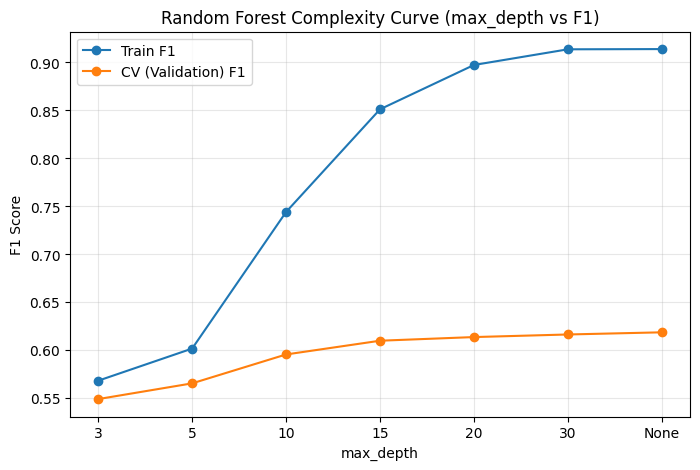

In [ ]:
from sklearn.model_selection import cross_val_score

depth_values = [3, 5, 10, 15, 20, 30, None]
train_scores = []
val_scores = []

print("Building Random Forest complexity curve over max_depth...")

for depth in depth_values:
    # Start from the best params and override max_depth
    params = best_params.copy()
    params["max_depth"] = depth

    model = RandomForestClassifier(
        **params,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    # Train on full training data
    model.fit(X_train_lr, y_train_lr)

    # Train F1
    y_train_pred = model.predict(X_train_lr)
    train_f1 = f1_score(y_train_lr, y_train_pred)
    train_scores.append(train_f1)

    # Validation F1 via cross-validation
    cv_f1 = cross_val_score(
        model,
        X_train_lr,
        y_train_lr,
        cv=3,
        scoring="f1",
        n_jobs=-1
    ).mean()
    val_scores.append(cv_f1)

    print(f"max_depth={depth}: train F1={train_f1:.4f}, CV F1={cv_f1:.4f}")

# Plot
depth_labels = [str(d) for d in depth_values]
plt.figure(figsize=(8, 5))
plt.plot(depth_labels, train_scores, marker="o", label="Train F1")
plt.plot(depth_labels, val_scores, marker="o", label="CV (Validation) F1")
plt.xlabel("max_depth")
plt.ylabel("F1 Score")
plt.title("Random Forest Complexity Curve (max_depth vs F1)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Summary:
The Random Forest complexity analysis shows that shallow trees significantly underfit the data, with low validation F1 scores (e.g., depth = 3 gives F1 ≈ 0.55). As tree depth increases, validation performance steadily improves and peaks around depth ≈ 20 to unlimited depth, where F1 reaches roughly 0.61–0.62. The differences among deeper configurations are small, suggesting the model benefits from high capacity but eventually plateaus. Overall, this indicates the dataset is complex and high-variance: shallow trees underfit, while deeper trees slightly overfit but still yield the best generalization performance.

---
# Neural Networks

## Baseline model

### Implementation
We convert the deck lists into sparse vectors. To maximize data usage, we augment the dataset by flipping the player positions (P1 vs P2 becomes P2 vs P1), effectively doubling our training samples.

In [ ]:
import pandas as pd
import numpy as np
import json
import sqlite3
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, accuracy_score, confusion_matrix,
                             roc_curve, auc)

from xgboost import XGBClassifier, plot_importance

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, InputLayer, BatchNormalization, Dropout
from tensorflow.keras.optimizers import Adam

# Configuration
#DB_FILE = "/content/cr215.db" # File with 215k battles
DB_FILE = "/content/clash_royale.db" # Note: originally was trained on 215k datapoint
TEST_SIZE = 0.2
RANDOM_STATE = 42
BATCH_SIZE = 64 # This is fixed due to the data size

In [ ]:
def load_data():
    conn = sqlite3.connect(DB_FILE)
    query = "SELECT * FROM battles WHERE winner != 0"
    df = pd.read_sql_query(query, conn)
    conn.close()
    return df

def evaluate_and_plot(model, X_test, y_test, history=None, model_type='Keras', xgb_results=None):
    # Generate Predictions
    if model_type == 'Keras':
        y_probs = model.predict(X_test, verbose=0).ravel()
        y_pred = (y_probs > 0.5).astype(int)
    elif model_type == 'XGBoost':
        y_probs = model.predict_proba(X_test)[:, 1]
        y_pred = model.predict(X_test)
    else: # Simple models (Sklearn)
        y_probs = model.predict_proba(X_test)[:, 1]
        y_pred = model.predict(X_test)

    # Printing Metrics
    acc = accuracy_score(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_probs)
    roc_auc = auc(fpr, tpr)

    print(f"--- {model_type} Performance ---")
    print(f"Accuracy: {acc:.4f}")
    print(f"ROC AUC:  {roc_auc:.4f}")
    print("-" * 30)
    print(classification_report(y_test, y_pred))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Plot A: Learning Curves
    ax = axes[0]
    if model_type == 'Keras' and history:
        ax.plot(history.history['loss'], label='Train Loss')
        ax.plot(history.history['val_loss'], label='Val Loss')
        ax.set_title('Keras Learning Curve')
        ax.set_xlabel('Epochs')
        ax.set_ylabel('Loss')
        ax.legend()
    elif model_type == 'XGBoost' and xgb_results:
        epochs = len(xgb_results['validation_0']['logloss'])
        x_axis = range(0, epochs)
        ax.plot(x_axis, xgb_results['validation_0']['logloss'], label='Train')
        ax.plot(x_axis, xgb_results['validation_1']['logloss'], label='Test')
        ax.set_title('XGBoost Learning Curve')
        ax.legend()
    else:
        ax.text(0.5, 0.5, 'No History Available\n(Simple Model)',
                ha='center', va='center', fontsize=12)
        ax.set_title('Learning Curve')

    # Plot B: Confusion Matrix
    ax = axes[1]
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title('Confusion Matrix')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

    # Plot C: ROC Curve
    ax = axes[2]
    ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.2f}')
    ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    ax.set_title('ROC Curve')
    ax.legend(loc="lower right")

    plt.tight_layout()
    plt.show()

    return acc

In [ ]:
# Basic card centric
def process_baseline_data(df):
    df = df.copy()
    df['label'] = df['winner'].apply(lambda x: 1 if x == 1 else 0)

    for col in ['player1_deck', 'player2_deck']:
        df[col] = df[col].apply(lambda x: json.loads(x) if isinstance(x, str) else [])

    all_cards = set()
    for deck in df['player1_deck']: all_cards.update(deck)
    for deck in df['player2_deck']: all_cards.update(deck)

    card_to_idx = {cid: i for i, cid in enumerate(sorted(all_cards))}
    num_cards = len(card_to_idx)

    def get_vector(row, prefix):
        vec = np.zeros(num_cards, dtype='int8')
        for cid in row[f'{prefix}_deck']:
            if cid in card_to_idx: vec[card_to_idx[cid]] = 1
        return vec

    p1_vecs = np.stack(df.apply(lambda r: get_vector(r, 'player1'), axis=1).values)
    p2_vecs = np.stack(df.apply(lambda r: get_vector(r, 'player2'), axis=1).values)
    labels = df['label'].values

    X = np.concatenate([np.concatenate([p1_vecs, p2_vecs], axis=1),
                        np.concatenate([p2_vecs, p1_vecs], axis=1)], axis=0)
    y = np.concatenate([labels, 1-labels], axis=0)
    return X, y, X.shape[1]

# Cycles and Avg Elixir
def process_features_data_safe(df):
    conn = sqlite3.connect(DB_FILE)
    cards_df = pd.read_sql_query("SELECT card_id, elixir_cost FROM cards", conn)
    cards_df['elixir_cost'] = cards_df['elixir_cost'].fillna(3.0)
    elixir_map = dict(zip(cards_df['card_id'], cards_df['elixir_cost']))
    conn.close()

    df = df.copy()
    df['label'] = df['winner'].apply(lambda x: 1 if x == 1 else 0)
    for col in ['player1_deck', 'player2_deck']:
        df[col] = df[col].apply(lambda x: json.loads(x) if isinstance(x, str) else [])

    all_cards = set()
    for deck in df['player1_deck']: all_cards.update(deck)
    for deck in df['player2_deck']: all_cards.update(deck)
    card_to_idx = {cid: i for i, cid in enumerate(sorted(all_cards))}
    num_cards = len(card_to_idx)

    def get_stats(deck_ids):
        costs = [elixir_map.get(cid, 3.0) for cid in deck_ids]
        costs = [c if c is not None and not np.isnan(c) else 3.0 for c in costs]
        if not costs: return [0.0, 0.0]
        return [sum(costs)/len(costs)/5.0, sum(sorted(costs)[:4])/4.0/4.0] # Avg & Cycle

    def get_vector_with_stats(row, prefix):
        vec = np.zeros(num_cards, dtype='float32')
        deck = row[f'{prefix}_deck']
        for cid in deck:
            if cid in card_to_idx: vec[card_to_idx[cid]] = 1.0
        stats = np.array(get_stats(deck), dtype='float32')
        return np.concatenate([vec, stats])

    p1_vecs = np.stack(df.apply(lambda r: get_vector_with_stats(r, 'player1'), axis=1).values)
    p2_vecs = np.stack(df.apply(lambda r: get_vector_with_stats(r, 'player2'), axis=1).values)
    labels = df['label'].values

    X = np.concatenate([np.concatenate([p1_vecs, p2_vecs], axis=1),
                        np.concatenate([p2_vecs, p1_vecs], axis=1)], axis=0)
    y = np.concatenate([labels, 1-labels], axis=0)

    if np.isnan(X).any(): X = np.nan_to_num(X)
    return X, y, X.shape[1]

# Evo + Tower
def process_advanced_data(df):
    df = df.copy()
    df['label'] = df['winner'].apply(lambda x: 1 if x == 1 else 0)
    for col in ['player1_deck', 'player2_deck', 'player1_evos', 'player2_evos']:
        df[col] = df[col].apply(lambda x: json.loads(x) if isinstance(x, str) else [])

    all_cards = set()
    for deck in df['player1_deck']: all_cards.update(deck)
    for deck in df['player2_deck']: all_cards.update(deck)
    sorted_cards = sorted(list(all_cards))
    card_to_idx = {cid: i for i, cid in enumerate(sorted_cards)}

    all_towers = set(df['player1_tower_troop_id'].unique()) | set(df['player2_tower_troop_id'].unique())
    sorted_towers = sorted(list(all_towers))
    tower_to_idx = {tid: i for i, tid in enumerate(sorted_towers)}

    def get_player_vector(row, p_prefix):
        deck_vec = np.zeros(len(card_to_idx), dtype='int8')
        for cid in row[f'{p_prefix}_deck']:
            if cid in card_to_idx: deck_vec[card_to_idx[cid]] = 1

        evo_vec = np.zeros(len(card_to_idx), dtype='int8')
        for cid in row[f'{p_prefix}_evos']:
            if cid in card_to_idx: evo_vec[card_to_idx[cid]] = 1

        tower_vec = np.zeros(len(tower_to_idx), dtype='int8')
        tid = row[f'{p_prefix}_tower_troop_id']
        if tid in tower_to_idx: tower_vec[tower_to_idx[tid]] = 1
        return np.concatenate([deck_vec, evo_vec, tower_vec])

    p1_vecs = np.stack(df.apply(lambda r: get_player_vector(r, 'player1'), axis=1).values)
    p2_vecs = np.stack(df.apply(lambda r: get_player_vector(r, 'player2'), axis=1).values)
    labels = df['label'].values

    X = np.concatenate([np.concatenate([p1_vecs, p2_vecs], axis=1),
                        np.concatenate([p2_vecs, p1_vecs], axis=1)], axis=0)
    y = np.concatenate([labels, 1-labels], axis=0)

    feature_names = []
    for p in ['P1', 'P2']:
        feature_names += [f"{p}_Card_{c}" for c in sorted_cards]
        feature_names += [f"{p}_Evo_{c}" for c in sorted_cards]
        feature_names += [f"{p}_Tower_{t}" for t in sorted_towers]

    return X, y, X.shape[1], feature_names

In [ ]:
df_raw = load_data()
print(f"Loaded {len(df_raw)} matches.")

model_performance = {}

Loaded 56391 matches.



Training Simple NN (1 Hidden Layer)...
Epoch 1/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.5160 - loss: 0.6947 - val_accuracy: 0.5465 - val_loss: 0.6870
Epoch 2/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5658 - loss: 0.6799 - val_accuracy: 0.5677 - val_loss: 0.6791
Epoch 3/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5916 - loss: 0.6696 - val_accuracy: 0.5718 - val_loss: 0.6773
Epoch 4/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6032 - loss: 0.6603 - val_accuracy: 0.5803 - val_loss: 0.6740
Epoch 5/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6119 - loss: 0.6537 - val_accuracy: 0.5785 - val_loss: 0.6755
Epoch 6/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6226 - loss: 0.6472 - val_accuracy: 0.5820 - val_loss: 0.6735
Epoch 7/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6278 - loss: 0.6423 - val_accuracy: 0.5868 - val_loss: 0.6737
Epoch 8/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/s

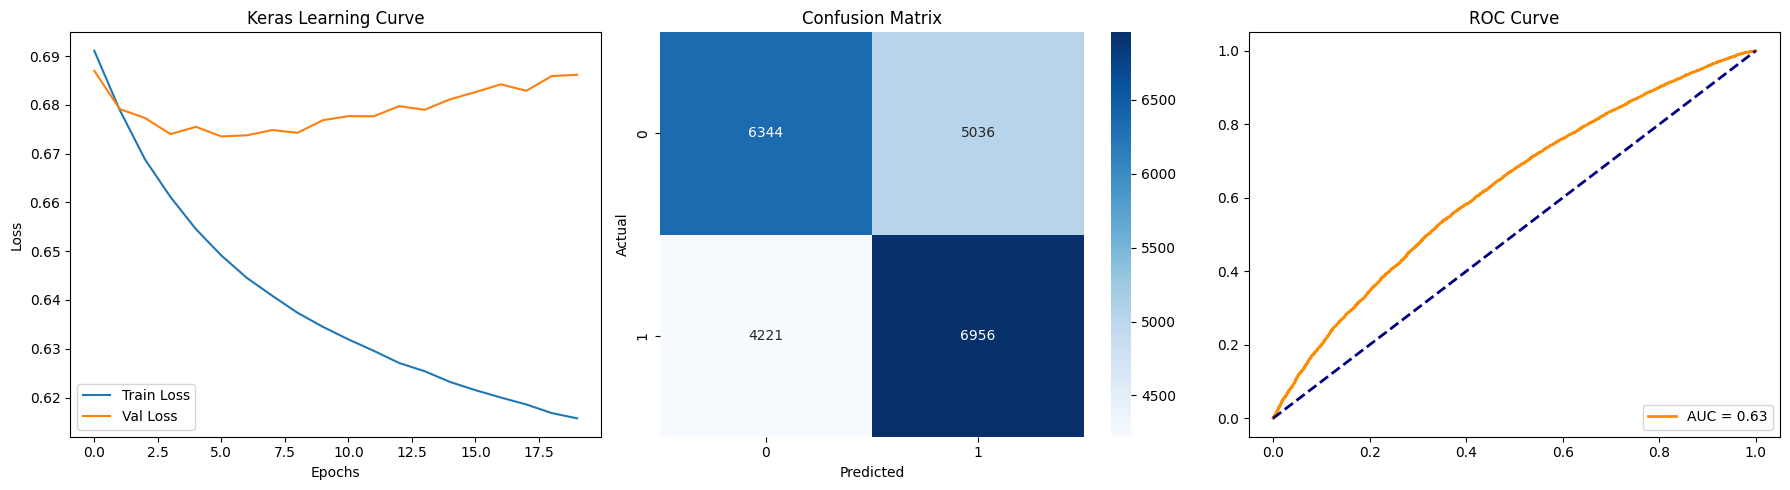


Training Simple NN (2 Hidden Layers)...
Epoch 1/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5196 - loss: 0.6919 - val_accuracy: 0.5567 - val_loss: 0.6845
Epoch 2/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5766 - loss: 0.6767 - val_accuracy: 0.5707 - val_loss: 0.6764
Epoch 3/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6046 - loss: 0.6606 - val_accuracy: 0.5785 - val_loss: 0.6737
Epoch 4/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6213 - loss: 0.6482 - val_accuracy: 0.5858 - val_loss: 0.6737
Epoch 5/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6364 - loss: 0.6370 - val_accuracy: 0.5880 - val_loss: 0.6750
Epoch 6/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6459 - loss: 0.6261 - val_accuracy: 0.5920 - val_loss: 0.6747
Epoch 7/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6574 - loss: 0.6167 - val_accuracy: 0.5909 - val_loss: 0.6797
Epoch 8/20
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/

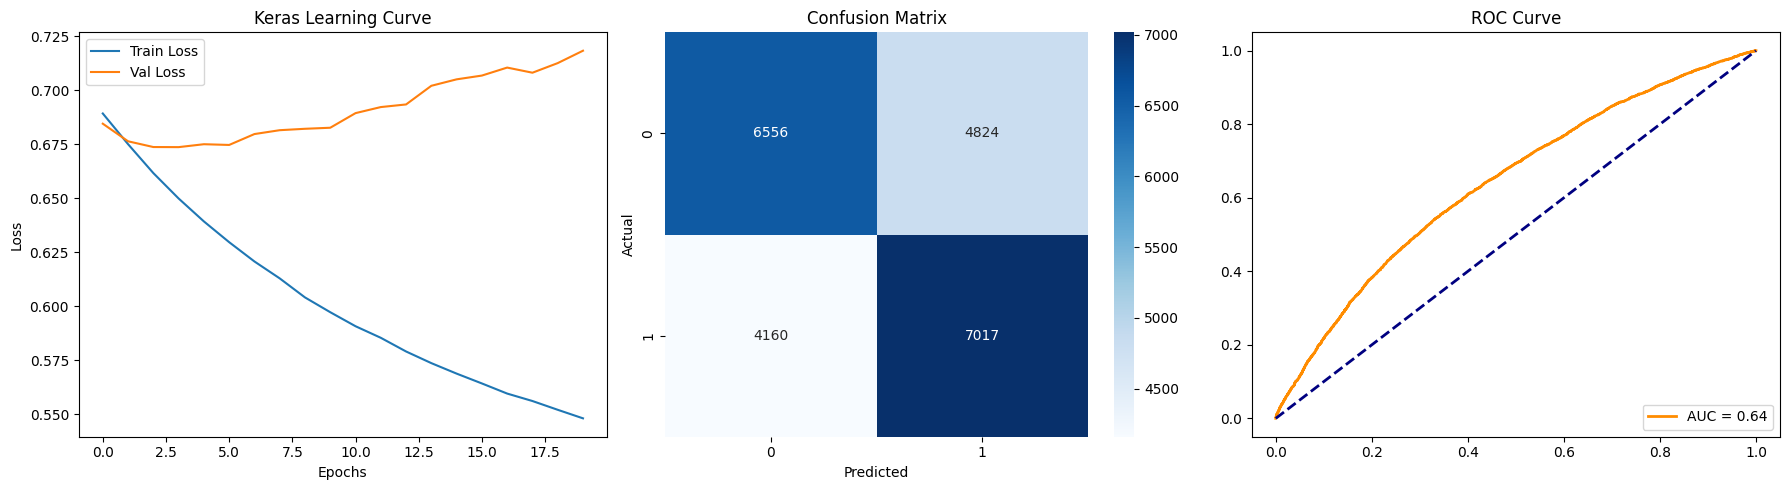

In [ ]:
# We use the baseline data pipeline as it is the simplest
X_base, y_base, dim_base = process_baseline_data(df_raw)
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_base, y_base, test_size=TEST_SIZE, random_state=RANDOM_STATE)

# Shallow just as a test to how much can one layer learn
print("\nTraining Simple NN (1 Hidden Layer)...")
simple_model_1 = Sequential([
    InputLayer(input_shape=(dim_base,)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
simple_model_1.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
hist_s1 = simple_model_1.fit(X_train_b, y_train_b, validation_data=(X_test_b, y_test_b),
                             epochs=20, batch_size=BATCH_SIZE, verbose=1)
acc_s1 = evaluate_and_plot(simple_model_1, X_test_b, y_test_b, history=hist_s1, model_type='Keras')
model_performance['Simple NN (1 Layer)'] = acc_s1


# Two Layers
print("\nTraining Simple NN (2 Hidden Layers)...")
simple_model_2 = Sequential([
    InputLayer(input_shape=(dim_base,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
simple_model_2.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
hist_s2 = simple_model_2.fit(X_train_b, y_train_b, validation_data=(X_test_b, y_test_b),
                             epochs=20, batch_size=BATCH_SIZE, verbose=1)
acc_s2 = evaluate_and_plot(simple_model_2, X_test_b, y_test_b, history=hist_s2, model_type='Keras')
model_performance['Simple NN (2 Layers)'] = acc_s2

If we look at the Loss plot of training and validation for the cases The validation loss plateus or even increases while the training loss continues to decrease. While both overfitted, they achieve 58% acc.

We now increase the complexity of the models by adding using a 3 layer architecture with differing degrees of dropout and early stopping.


Training NN (High Dropout 0.5, No Early Stopping)...
Epoch 1/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.4964 - loss: 0.7005 - val_accuracy: 0.4942 - val_loss: 0.6931
Epoch 2/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5029 - loss: 0.6933 - val_accuracy: 0.4957 - val_loss: 0.6932
Epoch 3/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5024 - loss: 0.6932 - val_accuracy: 0.4953 - val_loss: 0.6931
Epoch 4/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4989 - loss: 0.6931 - val_accuracy: 0.5174 - val_loss: 0.6927
Epoch 5/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5138 - loss: 0.6925 - val_accuracy: 0.5227 - val_loss: 0.6923
Epoch 6/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5177 - loss: 0.6917 - val_accuracy: 0.5259 - val_loss: 0.6915
Epoch 7/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5255 - loss: 0.6909 - val_accuracy: 0.5385 - val_loss: 0.6896
Epoch 8/30
1410/1410 ━━━━━━━━━━━━━━━

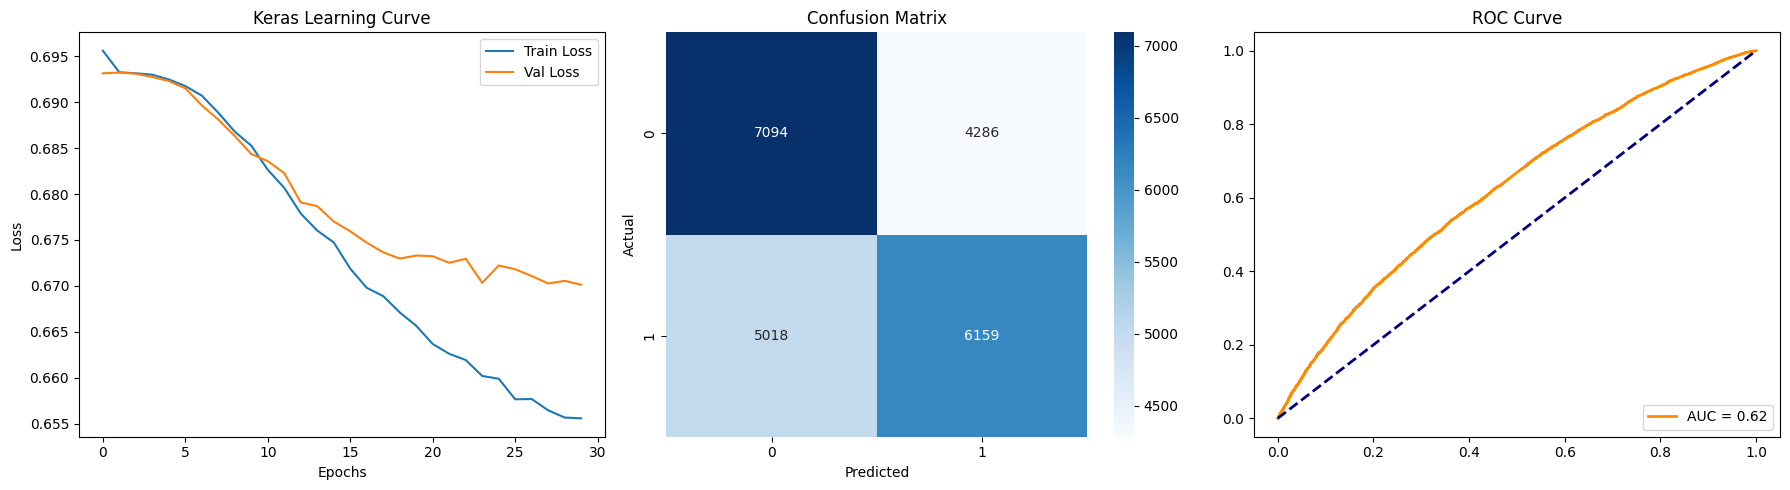


Training NN (Low Dropout 0.1, No Early Stopping)...
Epoch 1/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.5108 - loss: 0.6934 - val_accuracy: 0.5346 - val_loss: 0.6883
Epoch 2/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5450 - loss: 0.6858 - val_accuracy: 0.5581 - val_loss: 0.6823
Epoch 3/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5672 - loss: 0.6776 - val_accuracy: 0.5706 - val_loss: 0.6777
Epoch 4/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5911 - loss: 0.6684 - val_accuracy: 0.5706 - val_loss: 0.6767
Epoch 5/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5995 - loss: 0.6621 - val_accuracy: 0.5771 - val_loss: 0.6758
Epoch 6/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6122 - loss: 0.6538 - val_accuracy: 0.5804 - val_loss: 0.6749
Epoch 7/30
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6191 - loss: 0.6492 - val_accuracy: 0.5847 - val_loss: 0.6729
Epoch 8/30
1410/1410 ━━━━━━━━━━━━━━━━

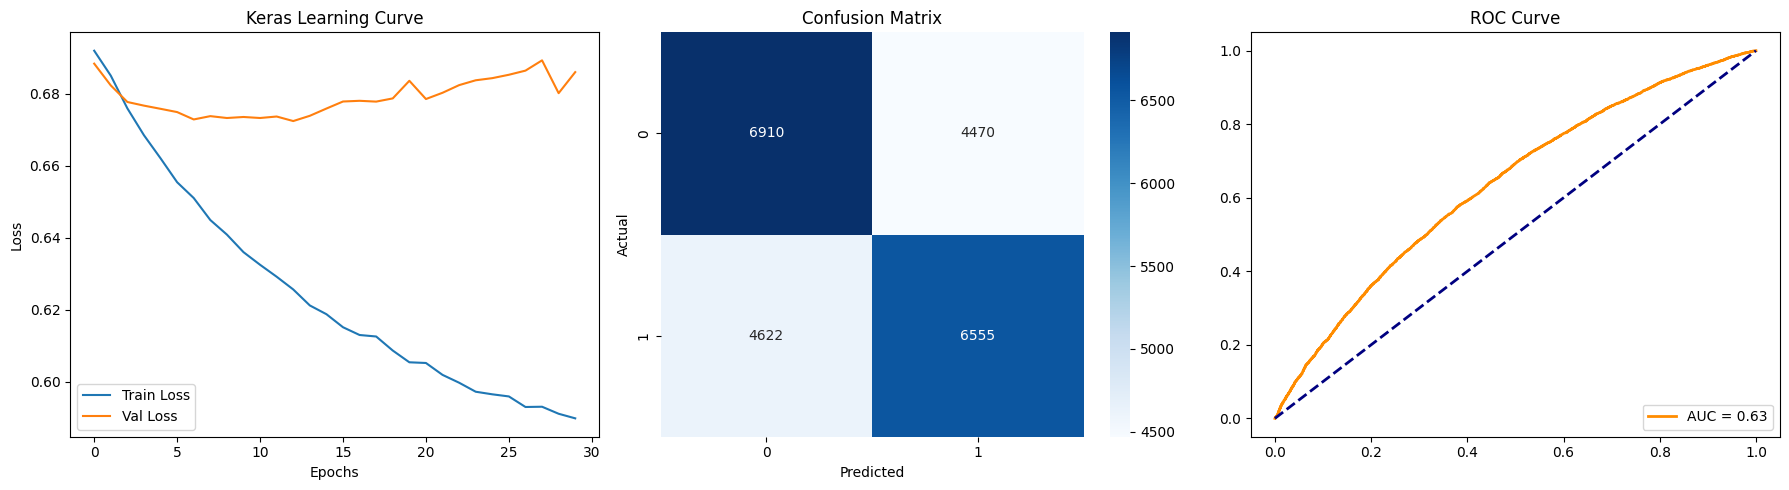


Training NN (Balanced Dropout 0.3 + Early Stopping)...
--- Keras Performance ---
Accuracy: 0.5906
ROC AUC:  0.6272
------------------------------
              precision    recall  f1-score   support

           0       0.59      0.61      0.60     11380
           1       0.59      0.58      0.58     11177

    accuracy                           0.59     22557
   macro avg       0.59      0.59      0.59     22557
weighted avg       0.59      0.59      0.59     22557



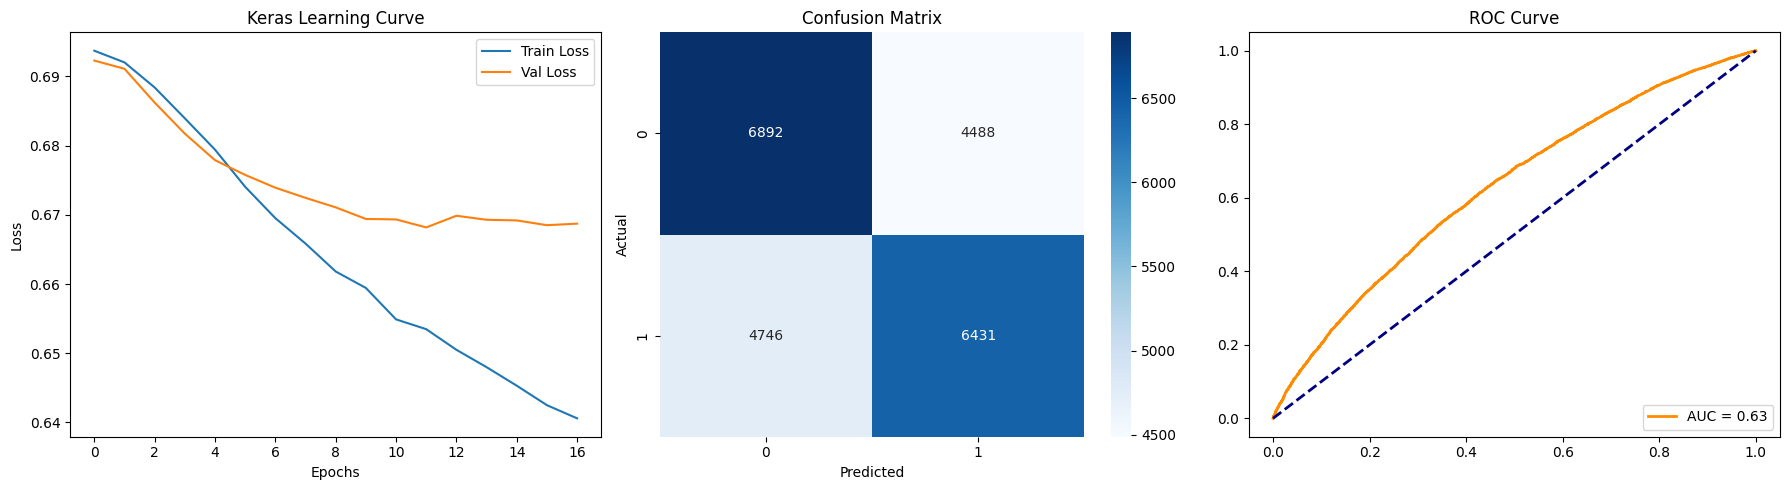

In [ ]:
# Will reuse to build 3 layer arch with varying Dropout
def build_3layer_model(input_dim, dropout_rate=0.0):
    model = Sequential([
        InputLayer(input_shape=(input_dim,)),
        Dense(64, activation='relu'),
        Dropout(dropout_rate),
        Dense(32, activation='relu'),
        Dropout(dropout_rate),
        Dense(16, activation='relu'),
        Dropout(dropout_rate),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
    return model

# High Dropout, No Early Stopping: testing if we can force underfitting or slower convergence
print("\nTraining NN (High Dropout 0.5, No Early Stopping)...")

model_high_do = build_3layer_model(dim_base, dropout_rate=0.5)
hist_high = model_high_do.fit(X_train_b, y_train_b, validation_data=(X_test_b, y_test_b),
                              epochs=30, batch_size=BATCH_SIZE, verbose=1)
acc_high = evaluate_and_plot(model_high_do, X_test_b, y_test_b, history=hist_high, model_type='Keras')
model_performance['NN (High Dropout)'] = acc_high

# Low Dropout, No Early Stopping: testing if we overfit without enough regularization
print("\nTraining NN (Low Dropout 0.1, No Early Stopping)...")

model_low_do = build_3layer_model(dim_base, dropout_rate=0.1)
hist_low = model_low_do.fit(X_train_b, y_train_b, validation_data=(X_test_b, y_test_b),
                            epochs=30, batch_size=BATCH_SIZE, verbose=1)
acc_low = evaluate_and_plot(model_low_do, X_test_b, y_test_b, history=hist_low, model_type='Keras')
model_performance['NN (Low Dropout)'] = acc_low

# Balanced Dropout and Early Stopping: this leads directly to why we choose our given optimized model
print("\nTraining NN (Balanced Dropout 0.3 + Early Stopping)...")

model_es = build_3layer_model(dim_base, dropout_rate=0.3)
es_callback = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
hist_es = model_es.fit(X_train_b, y_train_b, validation_data=(X_test_b, y_test_b),
                       epochs=50, batch_size=BATCH_SIZE, callbacks=[es_callback], verbose=0)
acc_es = evaluate_and_plot(model_es, X_test_b, y_test_b, history=hist_es, model_type='Keras')
model_performance['NN (Early Stopping)'] = acc_es

A pattern emerges, when we use low to now Dropout we see that our validation loss can increase. This will not necessarily be reproducible but something to take note of. Early stopping addresses this issue of increasing loss directly, while higher Dropout seems to reduce the likelihood of it ocurring. Again, all models seem to plateu at about 58% (with the best model scoring 0.5806). The High Dropout + Early Stopping model and the High Dropout model ended with a difference in loss between training and testing of about 0.01 and 0.005 respectively. This does not imply that High Dropout is better than Dropout + Early Stopping.

# Fighting Overfitting
The previous graphs showed the validation loss plateauing and increasing. We aboserved how **Early Stopping** and **Higher Dropout** to force the model to generalize better (visually seem as the validation loss decreasing at a similar rate than the training loss, up to a point). We expect the curves to stay closer together.

Note: Running the cell below takes about 15mins. I have a GPU in my laptop which allows for training NN's significantly faster. More tests were performed locally.

We also used the advanced dataset which includes 492 features, where each player has 121 + 121 + 4 one hot encoded entries.

In [ ]:
X_adv, y_adv, input_dim_adv, feature_names = process_advanced_data(df_raw)

# Split
X_train, X_test, y_train, y_test = train_test_split(X_adv, y_adv, test_size=TEST_SIZE, random_state=RANDOM_STATE)

print(f"Advanced Input Dimension: {input_dim_adv}")

Advanced Input Dimension: 492


Epoch 1/50
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.5027 - loss: 0.7537 - val_accuracy: 0.5157 - val_loss: 0.6941 - learning_rate: 5.0000e-04
Epoch 2/50
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.5096 - loss: 0.7006 - val_accuracy: 0.5228 - val_loss: 0.6908 - learning_rate: 5.0000e-04
Epoch 3/50
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.5123 - loss: 0.6957 - val_accuracy: 0.5322 - val_loss: 0.6896 - learning_rate: 5.0000e-04
Epoch 4/50
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.5175 - loss: 0.6933 - val_accuracy: 0.5381 - val_loss: 0.6880 - learning_rate: 5.0000e-04
Epoch 5/50
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.5292 - loss: 0.6906 - val_accuracy: 0.5488 - val_loss: 0.6859 - learning_rate: 5.0000e-04
Epoch 6/50
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.5389 - loss: 0.6879 - val_accuracy: 0.5517 - val_loss: 0.6841 - learning_rate: 5.0000e-04
Epoch 7/50
1410/1410 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/ste

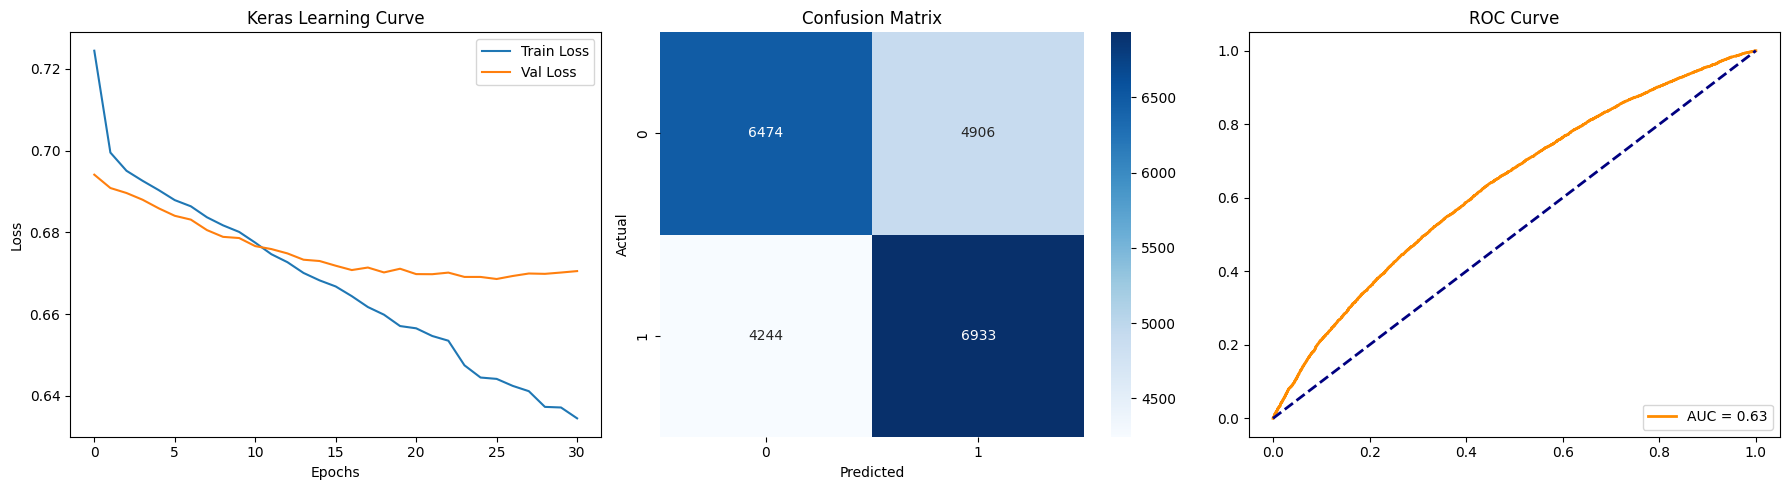

In [ ]:
NN_PARAMS = {
    "learning_rate": 0.0005,
    "batch_size": 64,
    "dropout_rate": 0.5,
    "layers": [128, 64, 32],
    "optimizer": "Adam",
    "early_stopping_patience": 5
}

def build_optimized_model(input_dim):
    model = tf.keras.Sequential([
        tf.keras.layers.InputLayer(input_shape=(input_dim,)),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=NN_PARAMS["learning_rate"]),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

callbacks = [
    EarlyStopping(monitor='val_loss', patience=NN_PARAMS["early_stopping_patience"], restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)
]

# Train NN
nn_model = build_optimized_model(input_dim_adv)
history_nn = nn_model.fit(X_train, y_train, validation_data=(X_test, y_test),
                          epochs=50, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)

acc_nn = evaluate_and_plot(nn_model, X_test, y_test, history=history_nn, model_type='Keras')
model_performance['Neural Network'] = acc_nn

This model achieved 59% accuracy, a slight improvement but with significant computation.

# Accuracy ceiling (~60%)?
Despite normalizing the features, the Neural Network struggled to effectively utilize the Elixir and Cycle stats, converging to a near-random baseline (50-60%). This suggests that the loss landscape is difficult for gradient descent to navigate with these mixed feature types (sparse binary cards vs. dense continuous stats). We will switch to XGBoost.

The Neural Network struggled in previous experiments and seem to be converging to a baseline (58-60%). This suggests that the loss landscape is difficult for gradient descent to navigate with these mixed feature types (sparse binary cards vs. dense continuous stats). We will switch to XGBoost.

We run Grid Search on XGBoost knowing before hand that it takes significantly less than NN. Thus it is "more" suitable for this expensive operation. Our aim is to find the best model given the parameters. We have run similar GridCV before and discovered these are good parameters [Previous Grid Search CV](https://docs.google.com/spreadsheets/d/19K3o4U9-vphqYja7943Ib5qTKFPX6SAkBo-RlAs6dyg/edit?usp=sharing)

In [ ]:
param_grid = {
    'n_estimators': [500, 1000],
    'learning_rate': [0.01, 0.05],
    'max_depth': [3, 6],
    'subsample': [0.7, 1.0],
    'colsample_bytree': [0.7, 1.0]
}

grid = ParameterGrid(param_grid)
best_xgb_acc = 0
best_xgb_params = None

print(f"Searching {len(grid)} combinations...")

for params in grid:
    xgb_temp = XGBClassifier(**params, n_jobs=-1, eval_metric="logloss", early_stopping_rounds=10)
    xgb_temp.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

    preds = xgb_temp.predict(X_test)
    acc = accuracy_score(y_test, preds)

    if acc > best_xgb_acc:
        best_xgb_acc = acc
        best_xgb_params = params

print(f"Best XGB Accuracy: {best_xgb_acc:.4f}")
print(f"Best Params: {best_xgb_params}")

Searching 32 combinations...
Best XGB Accuracy: 0.6119
Best Params: {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 1000, 'subsample': 0.7}


We see that the added features are infact really good predictors. The plot above represents which features are the most important and `f244, f245, f121, f122` all coincide with the **Average Elixir** and **Cycle Cost** of player 1 (121, 122) and 2 (244, 245).

# XGBoost Best Model

--- Phase 3c: Final XGBoost Model ---
--- XGBoost Performance ---
Accuracy: 0.6119
ROC AUC:  0.6562
------------------------------
              precision    recall  f1-score   support

           0       0.62      0.61      0.61     11380
           1       0.61      0.62      0.61     11177

    accuracy                           0.61     22557
   macro avg       0.61      0.61      0.61     22557
weighted avg       0.61      0.61      0.61     22557



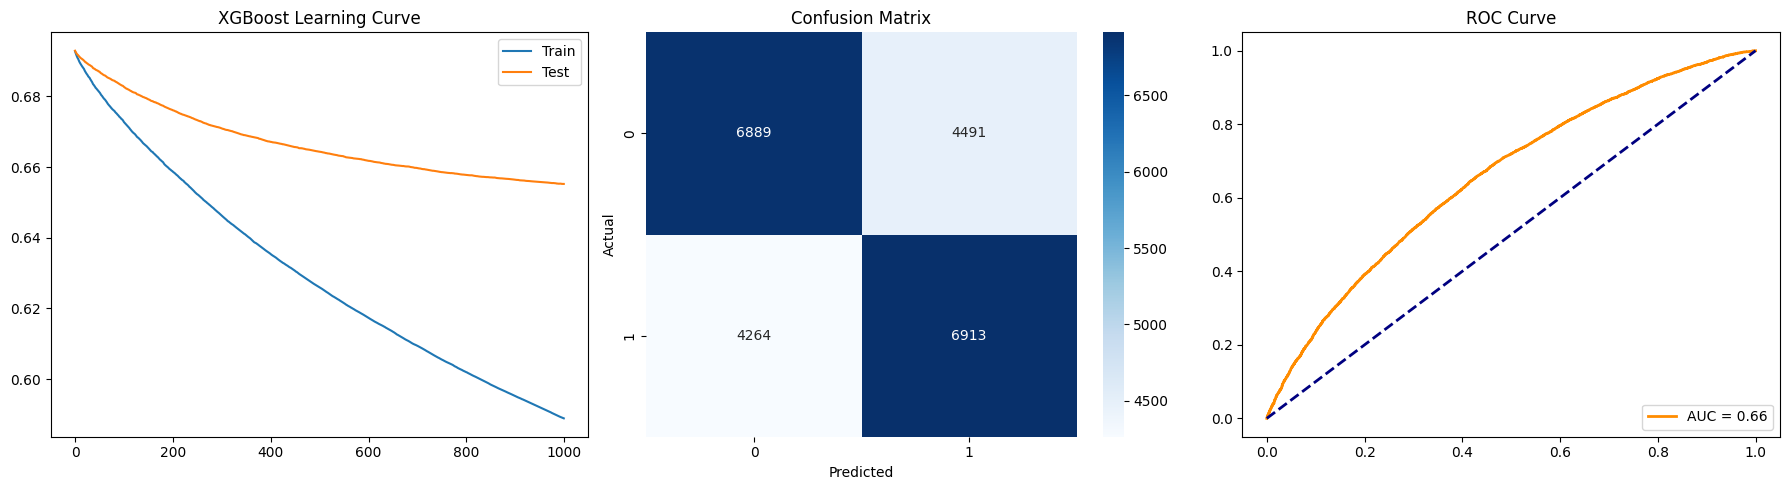

<Figure size 1000x800 with 0 Axes>

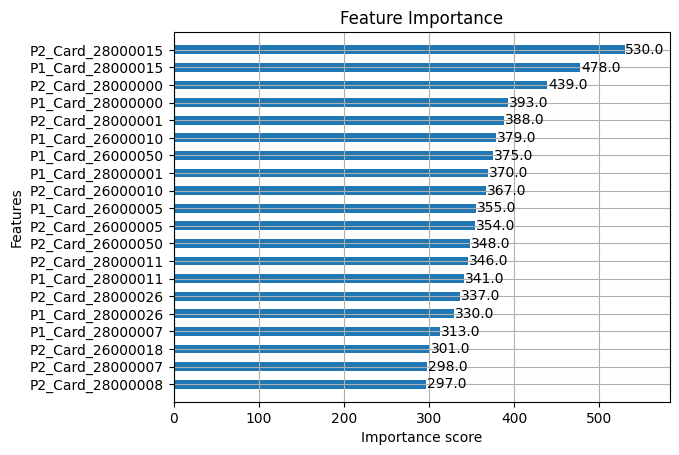

In [ ]:
print("--- Phase 3c: Final XGBoost Model ---")

xgb_final = XGBClassifier(**best_xgb_params, n_jobs=-1, eval_metric=["logloss", "error"])
xgb_final.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

xgb_results = xgb_final.evals_result()
acc_xgb = evaluate_and_plot(xgb_final, X_test, y_test, xgb_results=xgb_results, model_type='XGBoost')
model_performance['XGBoost'] = acc_xgb

# Feature Importance
plt.figure(figsize=(10, 8))
# Map generic feature names to specific names for the plot
xgb_final.get_booster().feature_names = feature_names
plot_importance(xgb_final, max_num_features=20, height=0.5, title="Feature Importance")
plt.show()

# Stacking: NN and XGBoost

--- Phase 4: Stacking Ensemble ---
705/705 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Stacking Results:
--- Stacking (LogReg) Performance ---
Accuracy: 0.6134
ROC AUC:  0.6589
------------------------------
              precision    recall  f1-score   support

           0       0.61      0.63      0.62      5687
           1       0.61      0.60      0.61      5592

    accuracy                           0.61     11279
   macro avg       0.61      0.61      0.61     11279
weighted avg       0.61      0.61      0.61     11279



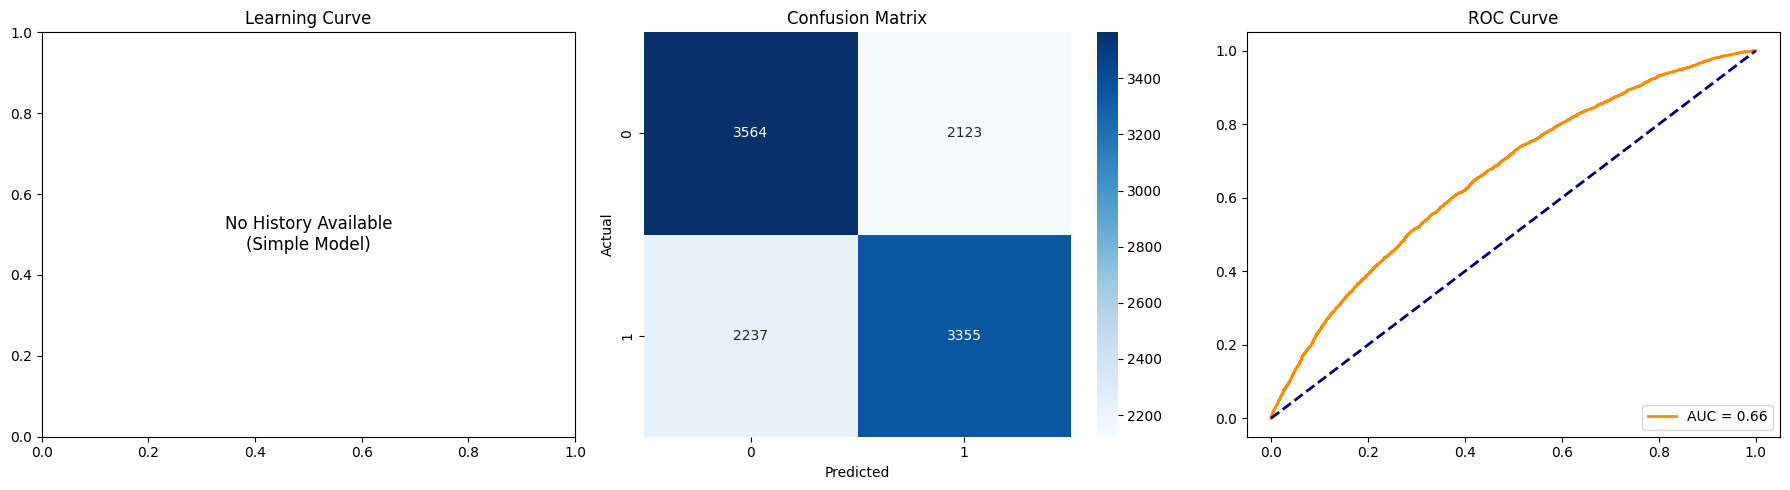

In [ ]:
print("--- Phase 4: Stacking Ensemble ---")

nn_probs = nn_model.predict(X_test).ravel()
xgb_probs = xgb_final.predict_proba(X_test)[:, 1]

# Meta features
X_stack = np.column_stack((nn_probs, xgb_probs))

# Split Meta-data (Train/Val split on the Test set to avoid leakage
X_meta_train, X_meta_test, y_meta_train, y_meta_test = train_test_split(
    X_stack, y_test, test_size=0.5, random_state=42
)

# Train Logistic Reg
meta_model = LogisticRegression()
meta_model.fit(X_meta_train, y_meta_train)

# Evaluate
print("Stacking Results:")
acc_stack = evaluate_and_plot(meta_model, X_meta_test, y_meta_test, model_type='Stacking (LogReg)')
model_performance['Stacking Ensemble'] = acc_stack

Best Performing model by far, as we hypothesized 60% accuracy and 64% AUC.

# AdaBoost

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report, confusion_matrix
)
from sklearn.model_selection import ParameterGrid, learning_curve
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure numerical_cols exist in X_train
numerical_cols_existing = [c for c in numerical_cols if c in X_train.columns]

# Scale only existing numerical columns
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numerical_cols_existing] = scaler.fit_transform(X_train[numerical_cols_existing])
X_test_scaled[numerical_cols_existing] = scaler.transform(X_test[numerical_cols_existing])

# Ensure y_train/y_test are Series
y_train = pd.Series(y_train)
y_test = pd.Series(y_test)

# --- AdaBoost Grid Search ---
ada_params = {
    "n_estimators": [200, 400, 600],
    "learning_rate": [0.5, 0.2, 0.1],
    "max_depth": [2, 3, 4],
}

grid = list(ParameterGrid(ada_params))
print(f"--- Starting AdaBoost Grid Search over {len(grid)} configurations ---")

best_ada = None
best_test_acc = 0
best_params = None
results = []

for i, params in enumerate(grid):
    print(f"Testing {i+1}/{len(grid)}: {params}", end="\r")

    base_tree = DecisionTreeClassifier(
        max_depth=params["max_depth"],
        random_state=42
    )

    ada = AdaBoostClassifier(
        estimator=base_tree,
        n_estimators=params["n_estimators"],
        learning_rate=params["learning_rate"],
        algorithm="SAMME",
        random_state=42
    )

    ada.fit(X_train_scaled, y_train)

    # Predictions
    train_preds = ada.predict(X_train_scaled)
    test_preds = ada.predict(X_test_scaled)
    train_acc = accuracy_score(y_train, train_preds)
    test_acc = accuracy_score(y_test, test_preds)

    results.append({
        **params,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc
    })

    if test_acc > best_test_acc:
        best_test_acc = test_acc
        best_ada = ada
        best_params = params

print("\nAdaBoost Grid Search Finished!")
print(f"Best Test Accuracy: {best_test_acc:.4f}")
print(f"Best Params: {best_params}")

# --- Save results ---
ada_results_df = pd.DataFrame(results).sort_values(by='test_accuracy', ascending=False).reset_index(drop=True)
print("\n--- Top 5 AdaBoost Configurations ---")
print(ada_results_df.head(5))
ada_results_df.to_csv("adaboost_gridsearch_results.csv", index=False)

# --- Feature Importance ---
importances = pd.Series(best_ada.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("\nTop 20 AdaBoost Feature Importances:")
print(importances.head(20))
importances.head(20).to_csv("adaboost_top_features.csv")

# --- Evaluation Metrics ---
print("\n=== AdaBoost Evaluation ===")
y_pred = best_ada.predict(X_test_scaled)
y_proba = best_ada.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC AUC  : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("AdaBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# --- ROC Curve ---
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1], [0,1], "k--")
plt.title("AdaBoost - ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

# --- Learning Curve ---
train_sizes, train_scores, test_scores = learning_curve(
    best_ada, X_train_scaled, y_train, cv=5, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5), scoring='accuracy'
)

plt.figure(figsize=(6,5))
plt.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', label='Train')
plt.plot(train_sizes, np.mean(test_scores, axis=1), 'o-', label='Validation')
plt.title("AdaBoost Learning Curve")
plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Gradient Boost

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score

gb_params = {
    "n_estimators": [200, 400, 600],
    "learning_rate": [0.1, 0.05, 0.02],
    "max_depth": [2, 3, 4],
    "subsample": [1.0, 0.8],
}

grid = list(ParameterGrid(gb_params))
print(f"--- Starting Gradient Boosting Grid Search over {len(grid)} configurations ---")

best_gb = None
best_gb_acc = 0
best_gb_params = None
gb_results = []

for i, params in enumerate(grid):
    print(f"Testing {i+1}/{len(grid)}: {params}", end="\r")

    gb = GradientBoostingClassifier(
        n_estimators=params["n_estimators"],
        learning_rate=params["learning_rate"],
        max_depth=params["max_depth"],
        subsample=params["subsample"],
        random_state=42
    )

    gb.fit(X_train_scaled, y_train)

    preds = gb.predict(X_test_scaled)
    acc = accuracy_score(y_test, preds)

    gb_results.append({
        **params,
        "accuracy": acc
    })

    if acc > best_gb_acc:
        best_gb_acc = acc
        best_gb = gb
        best_gb_params = params

print("\nGradient Boosting Search Finished!")
print(f"Best Accuracy: {best_gb_acc:.4f}")
print(f"Best Params: {best_gb_params}")

gb_importances = pd.Series(best_gb.feature_importances_, index=X_train.columns)
gb_importances = gb_importances.sort_values(ascending=False)

print("\nTop Gradient Boosting Feature Importances:")
print(gb_importances.head(20))

In [ ]:
print("\n=== Gradient Boosting Evaluation ===")

# Predictions
y_pred = best_gb.predict(X_test_scaled)
y_proba = best_gb.predict_proba(X_test_scaled)[:, 1]

# Metrics
acc = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

# Overfitting gap
y_train_pred = best_gb.predict(X_train_scaled)
train_acc = accuracy_score(y_train, y_train_pred)
overfitting_gap = abs(train_acc - acc)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC AUC  : {roc_auc:.4f}")
print(f"Overfitting Gap: {overfitting_gap:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Player 2 Wins', 'Player 1 Wins']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Gradient Boosting - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}", color="green")
plt.plot([0,1], [0,1], "k--")
plt.title("Gradient Boosting - ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()